# Logística y satisfacción en Olist
### ¿Cuánto pesa la entrega en la experiencia del cliente?

**Diplomado:** Métodos estadísticos y matemáticos para la ciencia de datos · Facultad de Ciencias, UNAM

**Módulo I · Proyecto integrador**
* **Corona Rojas Emiliano**
* **Luna Hernández Miguel Angel**
* **Barrientos Bonilla Esmeralda**
* **Marín Montoya Pamela**
* **Rodríguez de Jesús Carlos Francisco**


**Preguntas de investigación**

1. ¿Cómo se relaciona el tiempo de entrega de los pedidos con el nivel de satisfacción de los clientes?
2. ¿Existe una asociación entre los meses de mayor volumen de pedidos y el incremento en los retrasos de entrega?

> Es un análisis **descriptivo y observacional**: muestra asociaciones, pero no demuestra que una variable cause la otra. Las dos preguntas usan unidades distintas: la primera estudia **pedidos**; la segunda, **meses de compra**.

**Contenido:**

0. Preparación

1. Comprensión de los datos

2. Calidad y decisiones

3. Pregunta 1

4. Pregunta 2  

5. Conclusiones


## 0. Introducción y preparación del entorno y de los datos
En el comercio electrónico, la experiencia de compra no termina al realizar un pedido, sino hasta que el cliente recibe su producto. En este proceso, los tiempos de entrega y el cumplimiento de las fechas prometidas pueden desempeñar un papel importante en su nivel de satisfacción.

Usamos los CSV públicos de Olist ([work-at-olist-data](https://github.com/olist/work-at-olist-data), commit `d9e4980`) que contienen información de aproximadamente 100,000 pedidos realizados en Brasil entre 2016 y 2018. Esta base incluye registros de compras, fechas estimadas y reales de entrega, así como calificaciones y reseñas de los clientes.

El notebook no usa rutas absolutas: busca los CSV en la variable de entorno `OLIST_DATA_DIR`, en `work-at-olist-data/datasets` o `data/raw` dentro de esta carpeta o de las superiores, y junto al repositorio del diplomado.

Solo leemos las dos tablas que necesitan las preguntas: `orders` (fechas y estado del pedido) y `reviews` (calificación y fechas de la encuesta).

In [3]:
#Importación de librerías y revisión de versiones

from pathlib import Path
import os
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.9
pandas: 2.3.3
NumPy: 2.3.5
Matplotlib: 3.10.6


In [4]:
#Listas de archivos de Olist a encontrar
ARCHIVOS = {
    "orders": "olist_orders_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
}

# Función del profesor para localizar los datos de Olist
def localizar_datos() -> Path:
    """Devuelve la carpeta con los CSV de Olist o indica cómo obtenerla."""
    candidatos = []
    definida = os.environ.get("OLIST_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())

    ubicacion = Path.cwd().resolve()
    for base in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base / "work-at-olist-data" / "datasets",
            base / "data" / "raw",
            base / "DMEMCD_2026" / "work-at-olist-data" / "datasets",
        ])

    for ruta in candidatos:
        if ruta.is_dir() and all((ruta / nombre).is_file() for nombre in ARCHIVOS.values()):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV de Olist. Clona https://github.com/olist/work-at-olist-data.git "
        "en esta carpeta, copia los dos CSV en data/raw/ o define OLIST_DATA_DIR."
    )

# Localización de los datos de Olist
DATA_DIR = localizar_datos()
print("Datos encontrados en:", DATA_DIR)

Datos encontrados en: C:\Users\Polly\DIPLOMADO\DMEMCD_2026\proyecto-logistica-satisfaccion-main\work-at-olist-data\datasets


### Lectura de las tablas

Siguiendo las buenas prácticas establecidas en el notebook 01 del curso, aplicamos dos criterios para garantizar el tratamiento adecuado de los datos. Primero, los identificadores (`*_id`) y los prefijos postales se manejan como **texto**, ya que representan etiquetas y no valores numéricos. Segundo, las columnas de fechas se convierten al formato datetime para facilitar el cálculo de diferencias entre ellas. Para evitar interrupciones durante la conversión, utilizamos `errors="coerce"` que convierten a `datetime` que transforma las fechas no válidas en valores faltantes (`NaT`). Posteriormente, identificaremos y contabilizaremos estos registros para evaluar la calidad de los datos.

In [5]:
# Diccionario para auomatizar la lectura de fechas en los CSV de Olist
COLUMNAS_FECHA = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
}

# Función para leer los CSV de Olist con identificadores como texto y fechas como datetime
def leer_tabla(nombre: str) -> pd.DataFrame:
    """Lee un CSV con identificadores como texto y fechas como datetime."""
    archivo = DATA_DIR / ARCHIVOS[nombre]
    columnas = pd.read_csv(archivo, nrows=0).columns
    como_texto = {
        columna: "string"
        for columna in columnas
        if columna.endswith("_id") or columna.endswith("_zip_code_prefix")
    }
    tabla = pd.read_csv(archivo, dtype=como_texto)
    for columna in COLUMNAS_FECHA.get(nombre, []):
        tabla[columna] = pd.to_datetime(tabla[columna], errors="coerce")
    return tabla

#Display de la cantidad de filas y columnas de cada tabla y las primeras 3 filas de cada una
TABLAS = {nombre: leer_tabla(nombre) for nombre in ARCHIVOS}
pedidos = TABLAS["orders"].copy()
resenas = TABLAS["reviews"].copy()

for nombre, tabla in TABLAS.items():
    print(f"{nombre:10s}: {len(tabla):>7,} filas × {tabla.shape[1]:>2} columnas")

display(pedidos.head(3))
display(resenas.head(3))

orders    :  99,441 filas ×  8 columnas
reviews   :  99,224 filas ×  7 columnas


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


### Estilo de las figuras

Definimos una sola vez el sistema visual, tomado de las versiones del equipo, para que todas las figuras sean consistentes: título a la izquierda que dice el hallazgo, subtítulo gris con la población, nota al pie con las limitaciones, **turquesa** para los pedidos que llegaron a tiempo y **coral** para los que llegaron tarde. Las figuras se guardan en `resultados/`.

In [6]:
#Personalización de plots
from matplotlib.ticker import FuncFormatter, MultipleLocator

TEMA = {
    "azul": "#17354A",
    "turquesa": "#138A88",
    "coral": "#E17B57",
    "gris": "#8998A4",
    "tinta": "#243947",
    "fondo": "#F7F9FB",
    "cuadricula": "#E3EAF0",
}
COLOR_A_TIEMPO = TEMA["turquesa"]
COLOR_TARDE = TEMA["coral"]
CARPETA_RESULTADOS = Path("resultados")
CARPETA_RESULTADOS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": TEMA["fondo"],
    "text.color": TEMA["tinta"],
    "axes.labelcolor": TEMA["tinta"],
    "xtick.color": TEMA["tinta"],
    "ytick.color": TEMA["tinta"],
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.titlecolor": TEMA["azul"],
    "axes.titlelocation": "left",
    "axes.titlepad": 28,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "grid.color": TEMA["cuadricula"],
    "grid.linewidth": 0.8,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
})


def subtitulo(ax, texto):
    """Escribe un subtítulo gris entre el título y el gráfico."""
    ax.text(0, 1.025, texto, transform=ax.transAxes, color=TEMA["gris"], fontsize=10)


def nota(ax, texto, y=-0.2):
    """Escribe una nota gris debajo del gráfico."""
    ax.text(0, y, texto, transform=ax.transAxes, color=TEMA["gris"], fontsize=9, va="top")


def guardar_figura(fig, nombre):
    """Guarda la figura en resultados/ con buena resolución."""
    fig.savefig(CARPETA_RESULTADOS / nombre, dpi=200, bbox_inches="tight")

## 1. Comprensión de los datos

### Unidades de observación y llaves

| Tabla | Una fila es… | Llave | Precaución |
|---|---|---|---|
| `orders` | un pedido | `order_id` | el estado del pedido condiciona qué fechas existen |
| `reviews` | una respuesta a la encuesta | `review_id` + `order_id` | un pedido puede tener varias reseñas o ninguna |

### Variables que usamos

| Variable | Tabla | Qué registra | Uso |
|---|---|---|---|
| `order_status` | orders | estado del pedido | elegir los pedidos entregados |
| `order_purchase_timestamp` | orders | fecha y hora de compra | inicio del tiempo de entrega; mes de compra |
| `order_delivered_customer_date` | orders | fecha y hora de entrega al cliente | fin del tiempo de entrega |
| `order_estimated_delivery_date` | orders | fecha prometida al cliente (sin hora) | definir si llegó tarde |
| `review_score` | reviews | calificación de 1 a 5 estrellas (ordinal) | satisfacción |
| `review_creation_date` | reviews | fecha en que **se envió** la encuesta | entender cuándo llega la encuesta |
| `review_answer_timestamp` | reviews | fecha y hora en que **se respondió** | elegir una reseña por pedido; momento de la respuesta |

Antes de unir tablas comprobamos en los datos si esas llaves se cumplen.

In [7]:
# Hacemos un dataframe para ver llaves únicas y repetidas en nuestras tablas de observación
chequeos = pd.DataFrame([
    {"tabla": "orders", "llave": "order_id",
     "filas": len(pedidos), "llaves_unicas": pedidos["order_id"].nunique()},
    {"tabla": "reviews", "llave": "order_id",
     "filas": len(resenas), "llaves_unicas": resenas["order_id"].nunique()},
])
chequeos["repetidas"] = chequeos["filas"] - chequeos["llaves_unicas"]
display(chequeos)

# Contamos cuántas reseñas (filas) existen por cada order_id
resenas_por_pedido = resenas.groupby("order_id").size()

# Algunos conteos útiles sobre reseñas y pedidos
print("Pedidos con más de una reseña:", (resenas_por_pedido > 1).sum())
print("Pedidos sin ninguna reseña:", (~pedidos["order_id"].isin(resenas["order_id"])).sum())
print("review_id que aparecen en más de un pedido:", resenas.groupby("review_id")["order_id"].nunique().gt(1).sum())
print("Reseñas cuyo pedido no existe en orders:", (~resenas["order_id"].isin(pedidos["order_id"])).sum())

assert pedidos["order_id"].is_unique, "order_id debe ser único en orders."

,tabla,llave,filas,llaves_unicas,repetidas
0,orders,order_id,99441,99441,0
1,reviews,order_id,99224,98673,551


Pedidos con más de una reseña: 547
Pedidos sin ninguna reseña: 768
review_id que aparecen en más de un pedido: 789
Reseñas cuyo pedido no existe en orders: 0


In [8]:
#dataframe con conteo de pedidos por estado y porcentaje de cada estado
estados = (
    pedidos["order_status"]
    .value_counts()
    .rename_axis("order_status")
    .to_frame("pedidos")
)
estados["porcentaje"] = (estados["pedidos"] / len(pedidos) * 100).round(2)
display(estados)

,pedidos,porcentaje
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


### Lo que encontramos

- `orders` tiene **99,441 pedidos** y `order_id` no se repite, así que **la unidad de observación de la pregunta 1 es el pedido**.
- **96,478 pedidos (97.02 %) están entregados.** Solo en ellos tiene sentido medir el tiempo de entrega o el retraso; en los demás, la falta de fecha de entrega es estructural.
- `reviews` tiene 99,224 filas, pero solo 98,673 pedidos distintos: **547 pedidos tienen más de una reseña** y 768 no tienen ninguna. Antes de unir las reseñas con los pedidos hay que decidir cuál conservar; si no, la unión multiplicaría pedidos.
- **789 `review_id` aparecen en más de un pedido**, así que `review_id` no sirve para quitar duplicados: la selección se hace por `order_id`. Todas las reseñas corresponden a un pedido que existe.

## 2. Calidad de los datos: diagnóstico antes que corrección

Como en el notebook 04 del curso, primero medimos y después decidimos. Cada decisión queda en un registro con cuántas filas afecta, para justificarla y poder revertirla. No se modifica ningún CSV.

In [9]:
# Función para documentar decisiones de limpieza de datos y análisis
registro = []


def registrar_decision(paso, tabla, criterio, filas_afectadas, accion, limitacion):
    """Anota una decisión de limpieza para documentarla al final."""
    registro.append({
        "paso": paso,
        "tabla": tabla,
        "criterio": criterio,
        "filas_afectadas": int(filas_afectadas),
        "accion": accion,
        "limitacion": limitacion,
    })

### 2.1 Fechas: conversión y faltantes

Comparamos los faltantes del CSV original (leído como texto) con los faltantes después de convertir a `datetime`. Si `errors="coerce"` hubiera encontrado fechas ilegibles, la diferencia lo mostraría.

In [10]:
# Manejo de errores después de convertir a datatime
fechas = COLUMNAS_FECHA["orders"]
crudo = pd.read_csv(DATA_DIR / ARCHIVOS["orders"], usecols=fechas, dtype="string")

auditoria_fechas = pd.DataFrame({
    "faltantes_en_csv": crudo.isna().sum(),
    "faltantes_tras_convertir": pedidos[fechas].isna().sum(),
})
auditoria_fechas["no_convertidas"] = (
    auditoria_fechas["faltantes_tras_convertir"] - auditoria_fechas["faltantes_en_csv"]
)
display(auditoria_fechas)

#df que contabiliza tipos de entrega y estado
sin_entrega_por_estado = (
    pedidos.assign(sin_fecha_entrega=pedidos["order_delivered_customer_date"].isna())
    .groupby("order_status")["sin_fecha_entrega"]
    .agg(pedidos="size", sin_fecha_entrega="sum")
    .sort_values("pedidos", ascending=False)
)
display(sin_entrega_por_estado)

,faltantes_en_csv,faltantes_tras_convertir,no_convertidas
order_purchase_timestamp,0,0,0
order_approved_at,160,160,0
order_delivered_carrier_date,1783,1783,0
order_delivered_customer_date,2965,2965,0
order_estimated_delivery_date,0,0,0


,pedidos,sin_fecha_entrega
order_status,,
delivered,96478,8
shipped,1107,1107
canceled,625,619
unavailable,609,609
invoiced,314,314
processing,301,301
created,5,5
approved,2,2


In [11]:
#Pedidos entregados y con fecha de entrega no nula
entregados = pedidos.loc[
    pedidos["order_status"].eq("delivered")
    & pedidos["order_delivered_customer_date"].notna()
].copy()

total_entregados = pedidos["order_status"].eq("delivered").sum()
print("Pedidos con estado delivered:", total_entregados)
print("Pedidos sin fecha de entrega:", total_entregados - len(entregados))
print("Base de análisis:", len(entregados))

#Registro de la decisión 1
registrar_decision(
    "Decisión 1", "orders", "estado distinto de delivered o sin fecha de entrega",
    len(pedidos) - len(entregados), "excluir de la base; no imputar fechas",
    "el análisis describe solo pedidos entregados",
)

Pedidos con estado delivered: 96478
Pedidos sin fecha de entrega: 8
Base de análisis: 96470


**Lo que muestran las fechas**

- Ninguna fecha fue ilegible: los faltantes después de convertir son los mismos que en el CSV.
- Los faltantes son casi todos **estructurales**: de los 2,965 pedidos sin fecha de entrega, 2,957 nunca se entregaron. No tiene sentido imputarles una fecha.
- Solo **8 pedidos marcados como entregados no tienen fecha de entrega**. También hay 6 cancelados que sí la tienen, una inconsistencia que no nos afecta porque quedan fuera.

**Decisión 1.** La base de análisis son los **96,470 pedidos entregados con fecha de entrega**. Los demás se excluyen sin imputar nada; en consecuencia, las conclusiones describen solo pedidos entregados.

### 2.2 Duraciones y secuencia de las fechas

Calculamos cuatro duraciones en días, conservando fracciones: tres etapas consecutivas y el tiempo total. Una etapa negativa significa que una fecha posterior del proceso quedó registrada antes que la anterior.

In [12]:
# Analizamos 4 secuencias de interés
ETAPAS = {
    "compra_aprobacion_dias": ("order_purchase_timestamp", "order_approved_at"),
    "aprobacion_transportista_dias": ("order_approved_at", "order_delivered_carrier_date"),
    "transportista_cliente_dias": ("order_delivered_carrier_date", "order_delivered_customer_date"),
    "total_dias": ("order_purchase_timestamp", "order_delivered_customer_date"),
}

# Desempaqueta la tupla de dos columnas por cada entrada del diccionario ETAPAS y restamos en formato fecha
for nombre, (inicio, fin) in ETAPAS.items():
    entregados[nombre] = (entregados[fin] - entregados[inicio]).dt.total_seconds() / 86400

columnas_duracion = list(ETAPAS)
auditoria_duraciones = pd.DataFrame({
    "faltantes": entregados[columnas_duracion].isna().sum(),
    "negativas": entregados[columnas_duracion].lt(0).sum(),
    "mediana": entregados[columnas_duracion].median().round(2),
    "maximo": entregados[columnas_duracion].max().round(1),
})
display(auditoria_duraciones)

# Conteos de secuencia: compra → aprobación → entrega al transportista → entrega y otras verificaciones de consistencia
etapas = columnas_duracion[:3]
entregados["secuencia_valida"] = entregados[etapas].ge(0).all(axis=1)
print("Pedidos con secuencia válida:", entregados["secuencia_valida"].sum())
print("Envío al transportista antes de la compra:",
      (entregados["order_delivered_carrier_date"] < entregados["order_purchase_timestamp"]).sum())
print("Tiempo total mayor a 100 días:", entregados["total_dias"].gt(100).sum())

# Registro de decisiones 2 y 3
registrar_decision(
    "Decisión 2", "orders", "alguna etapa negativa o faltante",
    (~entregados["secuencia_valida"]).sum(),
    "conservar: las fechas intermedias no se usan en las preguntas",
    "no se conoce la causa de las inconsistencias",
)
registrar_decision(
    "Decisión 3", "orders", "tiempo total mayor a 100 días",
    entregados["total_dias"].gt(100).sum(),
    "conservar; resumir con mediana y percentiles",
    "un valor atípico no es necesariamente un error",
)

,faltantes,negativas,mediana,maximo
compra_aprobacion_dias,14,0,0.01,30.9
aprobacion_transportista_dias,15,1350,1.82,125.8
transportista_cliente_dias,1,23,7.10,205.2
total_dias,0,0,10.22,209.6


Pedidos con secuencia válida: 95082
Envío al transportista antes de la compra: 165
Tiempo total mayor a 100 días: 64


**Lo que muestran las duraciones**

- El **tiempo total nunca es negativo**: la compra y la entrega siempre están en orden.
- Los problemas están en las fechas intermedias: **1,350 pedidos llegan al transportista antes de que se apruebe el pago** (165 incluso antes de la compra), 23 llegan al cliente antes que al transportista y 15 no tienen alguna fecha intermedia. En total, 1,388 pedidos no tienen una secuencia válida.
- 64 pedidos tardaron más de 100 días; el máximo es de 209.6 días.

**Decisión 2.** Conservamos los 1,388 pedidos con secuencia inválida. Sus errores están en las fechas intermedias (aprobación y entrega al transportista), que nuestras dos preguntas no usan: el tiempo total y el retraso solo dependen de la compra, la entrega y la fecha prometida, que son consistentes. Eliminarlos haría perder pedidos por un error que no afecta lo que medimos.

**Decisión 3.** Los pedidos de más de 100 días se conservan: son poco comunes, pero no hay evidencia de que sean errores, y una espera larga es justo parte del fenómeno que estudiamos. Para que no dominen los resúmenes usaremos mediana y percentiles en lugar de la media.

### 2.3 ¿Qué significa llegar tarde?

La fecha prometida (`order_estimated_delivery_date`) no trae hora: todas están a las 00:00. Si comparamos fecha y hora completas, un pedido entregado a las 10:00 del día prometido contaría como tarde. Por eso comparamos **días de calendario**:

$$\text{días tarde}_i = \text{día de entrega}_i - \text{día prometido}_i, \qquad \text{tarde}_i = \mathbb{1}(\text{días tarde}_i > 0).$$

In [13]:
# Verificación
estimada = entregados["order_estimated_delivery_date"]
print("Fechas prometidas con hora distinta de 00:00:", (estimada != estimada.dt.normalize()).sum())

# Procesamiento de fechas con retraso
entregados["dias_vs_estimada"] = (
    entregados["order_delivered_customer_date"] - estimada
).dt.total_seconds() / 86400
entregados["tarde"] = entregados["order_delivered_customer_date"].dt.normalize() > estimada

tarde_con_hora = entregados["dias_vs_estimada"].gt(0)
print(f"Tarde comparando días: {entregados['tarde'].sum():,} ({entregados['tarde'].mean():.2%})")
print(f"Tarde comparando fecha y hora: {tarde_con_hora.sum():,} ({tarde_con_hora.mean():.2%})")

# Registro de decisión 4
registrar_decision(
    "Decisión 4", "orders", "entregado el día prometido, después de las 00:00",
    (entregados["tarde"] != tarde_con_hora).sum(),
    "contar como a tiempo: se compara por día de calendario",
    "difiere del criterio de olist_tools.py (dias_retraso > 0)",
)

Fechas prometidas con hora distinta de 00:00: 0
Tarde comparando días: 6,534 (6.77%)
Tarde comparando fecha y hora: 7,826 (8.11%)


**Decisión 4.** Un pedido llega **tarde** si se entrega en un día posterior al prometido. Con este criterio hay **6,534 pedidos tarde (6.77 %)**. Si comparáramos fecha y hora serían 7,826 (8.11 %): los 1,292 de diferencia se entregaron el mismo día prometido. El criterio de `olist_tools.py` del curso (`dias_retraso > 0`) los cuenta como tarde; aquí no, porque el cliente recibió el pedido en la fecha que se le prometió.

### 2.4 Reseñas: una por pedido

Un pedido puede tener varias reseñas y la unidad de análisis es el pedido, así que necesitamos una sola por pedido. Las opciones razonables son:

| Opción | Ventaja | Problema |
|---|---|---|
| Conservar todas | no descarta nada | los pedidos con varias reseñas pesarían más y la unidad dejaría de ser el pedido |
| Promediar las calificaciones | usa todas las respuestas | puede dar valores como 2.5, que no existen en una escala ordinal de 1 a 5 |
| Primera respuesta | es una calificación real | ignora una opinión posterior distinta |
| **Última respuesta (elegida)** | es una calificación real y la opinión más reciente | no es necesariamente "la verdadera" |

Ordenamos por la fecha de **respuesta** (`review_answer_timestamp`) y desempatamos con la fecha de envío y el `review_id`, para que la elección sea reproducible. Después comprobamos si la regla cambia los resultados.

In [14]:
# Analisis de duplicados exactos de columnas con reseñas y rango válido de calificación
print("Filas exactamente repetidas:", resenas.duplicated().sum())
print("Calificaciones fuera de 1 a 5:", (~resenas["review_score"].between(1, 5)).sum())

# Pedidos con más de una reseña y cuántos de esos pedidos tienen calificaciones distintas entre sí
varias = resenas.groupby("order_id")["review_score"].agg(["size", "nunique"])
varias = varias[varias["size"] > 1]
print("Pedidos con más de una reseña:", len(varias))
print("Pedidos con calificaciones distintas entre sí:", (varias["nunique"] > 1).sum())

#orden a usar para el sort
orden_resenas = ["order_id", "review_answer_timestamp", "review_creation_date", "review_id"]

resenas_ordenadas = resenas.sort_values(orden_resenas, kind="stable")
resena_final = resenas_ordenadas.drop_duplicates("order_id", keep="last")
resena_inicial = resenas_ordenadas.drop_duplicates("order_id", keep="first")
assert resena_final["order_id"].is_unique

# Registro de decisión 5
registrar_decision(
    "Decisión 5", "reviews", "pedido con más de una reseña",
    len(resenas) - len(resena_final), "conservar la última respuesta (review_answer_timestamp)",
    "no se afirma que sea la más verdadera; se compara con la primera",
)

Filas exactamente repetidas: 0
Calificaciones fuera de 1 a 5: 0
Pedidos con más de una reseña: 547
Pedidos con calificaciones distintas entre sí: 202


### 2.5 Unir las reseñas con los pedidos

La unión es uno a uno porque ya dejamos una reseña por pedido; `validate="one_to_one"` lo comprueba y `indicator=True` muestra cuántos pedidos encontraron reseña.

In [15]:
analisis = entregados.merge(
    resena_final[["order_id", "review_score", "review_creation_date", "review_answer_timestamp"]],
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)
assert len(analisis) == len(entregados), "La unión duplicó pedidos."
display(analisis["_merge"].value_counts())

# Registro de decisión 6
con_resena = analisis["review_score"].notna()
registrar_decision(
    "Decisión 6", "reviews", "pedido entregado sin reseña",
    (~con_resena).sum(), "excluir solo del análisis de calificación",
    "no se imputan calificaciones",
)
print("Pedidos entregados con reseña:", con_resena.sum())

_merge
both          95824
left_only       646
right_only        0
Name: count, dtype: int64

Pedidos entregados con reseña: 95824


**Comprobación:** La suma 95,824 + 646 = 96,470 coincide exactamente con el total de pedidos entregados. Se tienen 95,824 pedidos entregados que sí encontraron su reseña en `resena_final`. Tienen datos completos de envío y calificación, y son los que se usarán para la Pregunta 1. En cambio, son 646 pedidos entregados que no tienen ninguna reseña.

### 2.6 ¿Cuándo recibió y cuándo respondió la encuesta el cliente?

La tabla `reviews` tiene dos fechas que no significan lo mismo: `review_creation_date` es el día en que Olist **envió** la encuesta y `review_answer_timestamp` es el momento en que el cliente la **respondió**. Para saber si alguien calificó antes de recibir su pedido hay que usar la segunda. Primero comprobamos en los datos que las columnas se comportan así y después vemos cuándo se envía la encuesta.

In [16]:
envio = resenas["review_creation_date"]
respuesta = resenas["review_answer_timestamp"]

#review_creation_date es la fecha de envío siempre a las 00:00
print(f"review_creation_date a las 00:00: {envio.eq(envio.dt.normalize()).mean():.1%}")

# Validación cronológica de envío  y respuesta
print(f"Respuestas iguales o posteriores al envío: {respuesta.ge(envio).mean():.1%}")

# Mediana de días entre envío y respuesta
print(f"Días entre envío y respuesta (mediana): {(respuesta - envio).dt.total_seconds().median() / 86400:.1f}")

"""
La regla de signos siempre es Fecha_A - Fecha_B:

Positivo (> 0): Fecha_A ocurrió después de Fecha_B.

Cero (0): Ambas ocurrieron el mismo día.

Negativo (< 0): Fecha_A ocurrió antes de Fecha_B.

"""

entrega = analisis["order_delivered_customer_date"]
analisis["respuesta_antes_entrega"] = analisis["review_answer_timestamp"] < entrega
analisis["envio_menos_entrega"] = (analisis["review_creation_date"] - entrega.dt.normalize()).dt.days
analisis["envio_menos_promesa"] = (
    analisis["review_creation_date"] - analisis["order_estimated_delivery_date"]
).dt.days

envio_encuesta = analisis[con_resena].groupby("tarde").agg(
    pedidos=("order_id", "size"),
    envio_dias_tras_entrega=("envio_menos_entrega", "median"),
    envio_dias_tras_promesa=("envio_menos_promesa", "median"),
    pct_enviada_antes_de_entrega=("envio_menos_entrega", lambda s: s.lt(0).mean() * 100),
    pct_respondida_antes_de_entrega=("respuesta_antes_entrega", lambda s: s.mean() * 100),
)
envio_encuesta.index = envio_encuesta.index.map({False: "A tiempo", True: "Tarde"})
display(envio_encuesta.round(1))

# Registro de decisión 7
antes = analisis["respuesta_antes_entrega"]
registrar_decision(
    "Decisión 7", "reviews", "respuesta registrada antes de la entrega",
    antes.sum(), "conservar y marcar; repetir resultados sin ellas como sensibilidad",
    "quitarlas excluye 70 % de los pedidos tardíos y cambia la población",
)
print(f"Respuestas anteriores a la entrega: {antes.sum():,}; de pedidos que llegaron tarde: {analisis.loc[antes, 'tarde'].mean():.1%}")

review_creation_date a las 00:00: 99.9%
Respuestas iguales o posteriores al envío: 100.0%
Días entre envío y respuesta (mediana): 1.7


,pedidos,envio_dias_tras_entrega,envio_dias_tras_promesa,pct_enviada_antes_de_entrega,pct_respondida_antes_de_entrega
tarde,,,,,
A tiempo,89443,1.0,-12.0,0.3,0.2
Tarde,6381,-4.0,2.0,74.5,70.1


Respuestas anteriores a la entrega: 4,653; de pedidos que llegaron tarde: 96.1%


**Lo que muestran las fechas de la encuesta**

- `review_creation_date` es la fecha de **envío**: está siempre a las 00:00 y la respuesta nunca es anterior a ella (llega una mediana de 1.7 días después). Por eso usamos `review_answer_timestamp` para saber cuándo calificó el cliente.
- **La encuesta se envía con una regla fija.** Si el pedido llega a tiempo, se envía al día siguiente de la entrega. Si se retrasa, se envía unos 2 días después de la fecha prometida (mediana), **aunque el pedido todavía no haya llegado**. Así, al 74.5 % de los pedidos tardíos se les envió la encuesta antes de recibirlos y el **70.1 % la respondió antes de la entrega**.
- De las 4,653 respuestas anteriores a la entrega, el 96.1 % son de pedidos tardíos. La regla de envío explica por qué hay tantas: la encuesta llega mientras el cliente sigue esperando.

**Decisión 7.** Conservamos las respuestas anteriores a la entrega: son la opinión real del cliente sobre una espera que ya rebasó lo prometido. Las marcamos (`respuesta_antes_entrega`) y repetimos los resultados sin ellas como **análisis de sensibilidad**, no como limpieza: el filtro quita el 0.2 % de los pedidos a tiempo, pero el 70.1 % de los tardíos, así que cambia qué pedidos se comparan.

### 2.7 Prueba de sensibilidad: ¿cambian los resultados con estas decisiones?

Comparamos la calificación a tiempo contra tarde con tres versiones de las reseñas: la última respuesta (nuestra elección), la primera, y la última sin las respuestas dadas antes de la entrega.

In [17]:
def resumen_calificacion(tabla):
    """Calificación media y porcentaje de reseñas bajas (1 o 2 estrellas), a tiempo contra tarde."""
    return tabla.groupby("tarde")["review_score"].agg(
        pedidos="size",
        media="mean",
        pct_baja=lambda s: s.le(2).mean() * 100,
    ).round(2)


con_primera = entregados.merge(
    resena_inicial[["order_id", "review_score"]], on="order_id", validate="one_to_one"
)
sensibilidad = pd.concat({
    "última respuesta (principal)": resumen_calificacion(analisis[con_resena]),
    "primera respuesta": resumen_calificacion(con_primera),
    "sin respuestas previas a la entrega": resumen_calificacion(analisis[con_resena & ~antes]),
})
display(sensibilidad)

pedidos  media  pct_baja
                                    tarde                          
última respuesta (principal)        False    89443   4.29      9.27
                                    True      6381   2.27     62.42
primera respuesta                   False    89443   4.29      9.26
                                    True      6381   2.27     62.36
sin respuestas previas a la entrega False    89263   4.29      9.25
                                    True      1908   3.72     19.44

**Lo que muestran las reseñas**

- No hay filas repetidas ni calificaciones fuera de 1 a 5. **547 pedidos tienen más de una reseña** (202 con calificaciones distintas) y 646 pedidos entregados no tienen ninguna.
- **Decisión 5.** Conservamos la última respuesta. La regla casi no importa: con la primera respuesta los resultados cambian en centésimas.
- **Decisión 6.** Los 646 pedidos sin reseña se quedan en la base, pero no entran al análisis de calificación; no se imputan calificaciones.
- **El filtro temporal sí cambia mucho el resultado.** Con todas las respuestas, el 62.4 % de los pedidos tardíos tiene 1 o 2 estrellas; con solo las respuestas posteriores a la entrega, el 19.4 %. Pero en esa versión quedan 1,908 de los 6,381 pedidos tardíos. Lo analizamos con cuidado en la sección 3.

### 2.8 Flujo de pedidos

Cuántos pedidos quedan después de cada criterio. La pregunta 1 usa los pedidos entregados con reseña; la pregunta 2 usa **todos** los pedidos para contar el volumen y los entregados para medir los retrasos. El registro completo de decisiones, con la decisión 8 de la pregunta 2, está en la sección 5.

In [18]:
flujo = pd.DataFrame({
    "paso": ["Pedidos en orders", "Con estado delivered", "Con fecha de entrega (base)", "Con reseña (pregunta 1)"],
    "pedidos": [len(pedidos), total_entregados, len(entregados), con_resena.sum()],
})
flujo["excluidos_en_el_paso"] = (flujo["pedidos"].shift(1) - flujo["pedidos"]).fillna(0).astype(int)
flujo["porcentaje_del_total"] = (flujo["pedidos"] / len(pedidos) * 100).round(2)
display(flujo)

,paso,pedidos,excluidos_en_el_paso,porcentaje_del_total
0,Pedidos en orders,99441,0,100.00
1,Con estado delivered,96478,2963,97.02
2,Con fecha de entrega (base),96470,8,97.01
3,Con reseña (pregunta 1),95824,646,96.36


## 3. Pregunta 1 · Tiempo de entrega y satisfacción

*¿Cómo se relaciona el tiempo de entrega de los pedidos con el nivel de satisfacción de los clientes?*

Medimos el tiempo de entrega de dos formas: el **tiempo total**, de la compra a la entrega, y los **días respecto de la fecha prometida** (negativos si el pedido llegó antes). La satisfacción es la calificación de 1 a 5 estrellas; para comparar grupos usamos también el porcentaje de **reseñas bajas (1 o 2 estrellas)**, un umbral que elegimos nosotros y no una definición universal. Usamos los 95,824 pedidos entregados que tienen reseña.

Las diferencias entre porcentajes se expresan en **puntos porcentuales (pp)**: pasar de 10 % a 40 % es una diferencia de 30 pp, no un aumento del 30 %.

In [19]:
calificados = analisis[con_resena].copy()
calificados["dias_tarde"] = (
    calificados["order_delivered_customer_date"].dt.normalize()
    - calificados["order_estimated_delivery_date"]
).dt.days

calificados["calificacion_baja"] = calificados["review_score"].le(2)

assert calificados["dias_tarde"].gt(0).eq(calificados["tarde"]).all(), "dias_tarde no coincide con tarde."
assert calificados["order_id"].is_unique
print("Pedidos entregados con reseña:", len(calificados))

Pedidos entregados con reseña: 95824


### 3.1 Cómo se distribuyen el tiempo de entrega y la calificación

In [20]:
# Distribución de los días de retraso y la calificación,
resumen_tiempos = calificados[["total_dias", "dias_tarde"]].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
).round(2)
display(resumen_tiempos)

# Frecuencia absoluta y porcentual de cada calificación (1 a 5 estrellas) ordenada de menor a mayor.
estrellas = calificados["review_score"].value_counts().sort_index().to_frame("pedidos")
estrellas["porcentaje"] = (estrellas["pedidos"] / len(calificados) * 100).round(2)
display(estrellas)

,total_dias,dias_tarde
count,95824.00,95824.00
mean,12.52,-11.91
std,9.46,10.11
min,0.53,-147.00
10%,4.15,-22.00
25%,6.76,-17.00
50%,10.21,-12.00
75%,15.66,-7.00
90%,23.03,-2.00
99%,45.85,18.00


,pedidos,porcentaje
review_score,,
1.0,9351,9.76
2.0,2921,3.05
3.0,7916,8.26
4.0,18888,19.71
5.0,56748,59.22


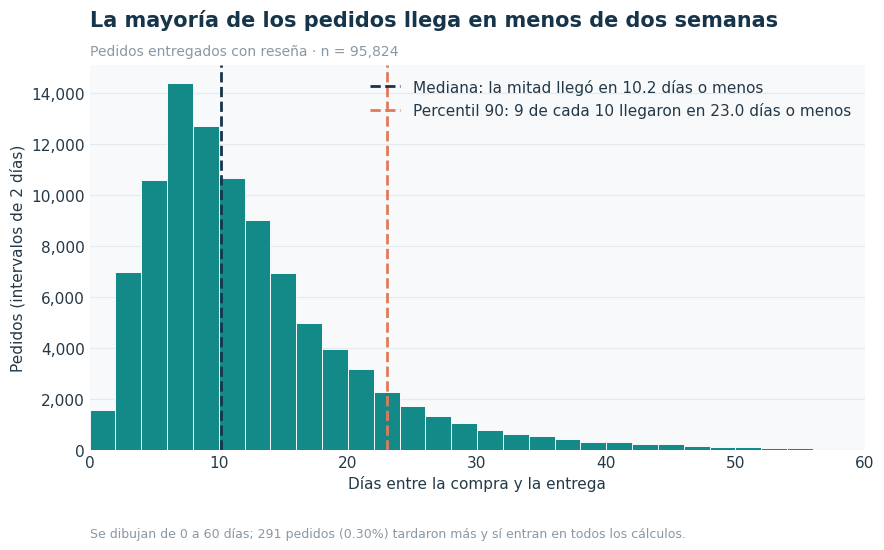

In [21]:
#Estadísticos calculados sobre todos los pedidos
mediana_total = calificados["total_dias"].median()
p90_total = calificados["total_dias"].quantile(0.90)
mas_de_60 = calificados["total_dias"].gt(60).sum()

fig, ax = plt.subplots(figsize=(10, 5))

# Histograma de 0 a 60 días con barras de 2 días de ancho.
ax.hist(calificados.loc[calificados["total_dias"].le(60), "total_dias"], bins=np.arange(0, 62, 2),
        color=TEMA["turquesa"], edgecolor=TEMA["fondo"], linewidth=0.7, zorder=3)
ax.axvline(mediana_total, color=TEMA["azul"], linestyle="--", linewidth=2,
           label=f"Mediana: la mitad llegó en {mediana_total:.1f} días o menos", zorder=4)
ax.axvline(p90_total, color=TEMA["coral"], linestyle="--", linewidth=2,
           label=f"Percentil 90: 9 de cada 10 llegaron en {p90_total:.1f} días o menos", zorder=4)

# Líneas verticales de referencia (mediana y percentil 90 globales).
ax.set(
    xlim=(0, 60),
    title="La mayoría de los pedidos llega en menos de dos semanas",
    xlabel="Días entre la compra y la entrega",
    ylabel="Pedidos (intervalos de 2 días)",
)
subtitulo(ax, f"Pedidos entregados con reseña · n = {len(calificados):,}")
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:,.0f}"))
ax.grid(axis="y", zorder=0)
ax.legend(frameon=False)

#Pie de figura
nota(ax, f"Se dibujan de 0 a 60 días; {mas_de_60:,} pedidos ({mas_de_60 / len(calificados):.2%}) tardaron más "
         "y sí entran en todos los cálculos.")
guardar_figura(fig, "figura_1_distribucion_tiempo_entrega.png")
plt.show()
plt.close(fig)

Como se menciona en el pie de figura, solo se recorta la vista para legibilidad; no se eliminan los 291 pedidos extremos de la muestra.

**Figura 1 y lo que muestran las distribuciones**

- **Qué muestra.** El tiempo total tiene **mediana de 10.21 días** (línea azul) y la mitad central de los pedidos tarda entre 6.76 y 15.66 días. El 68.8 % llega en dos semanas o menos, pero hay una cola larga a la derecha: el 10 % tarda más de 23 días (línea coral) y por eso la media (12.52) queda por encima de la mediana.
- El pedido típico llega **12 días antes de lo prometido** (mediana de `dias_tarde` = −12): las fechas prometidas son holgadas.
- La calificación está muy cargada a la derecha: **59.2 % da 5 estrellas** y 9.8 % da 1. Como la mediana es 5 en casi cualquier grupo, para comparar grupos usaremos la media y el porcentaje de **reseñas bajas (1 o 2 estrellas)**.
- **Limitaciones.** La figura muestra de 0 a 60 días para que se lea su forma; los 291 pedidos (0.30 %) que tardaron más no se dibujan, pero sí entran en todos los cálculos.

### 3.2 Calificación según el tiempo total de entrega

Agrupamos los pedidos en tramos con `pd.cut`. Los cortes son unidades de tiempo fáciles de leer (3 días, una, dos y tres semanas, un mes y mes y medio) y se fijaron antes de ver los resultados; no se eligieron para maximizar diferencias. Con `right=False` cada tramo incluye su límite inferior y excluye el superior: "7 a <14" va de 7 días a menos de 14. Los tramos tienen anchos distintos, así que no deben leerse como una escala lineal.

Medimos la asociación con la **correlación de Spearman**, que es la correlación de Pearson calculada sobre los **rangos** (los empates reciben el rango promedio):

$$\rho_s = \operatorname{corr}\big(\operatorname{rango}(\text{tiempo}_i),\ \operatorname{rango}(\text{estrellas}_i)\big).$$

Usamos Spearman y no Pearson porque la calificación es ordinal y el tiempo tiene una cola larga: Spearman solo usa el orden de los valores. Un valor negativo indica que a más tiempo tiende a haber menos estrellas; no dice cuántas estrellas se pierden por día ni implica causalidad.

In [22]:
def resumen_por(tabla, columna):
    """Pedidos, calificación media y porcentaje de reseñas bajas por grupo."""
    return tabla.groupby(columna, observed=True)["review_score"].agg(
        pedidos="size",
        media="mean",
        pct_baja=lambda s: s.le(2).mean() * 100,
    ).round(2)


#7 tramos de duración
cortes_total = [0, 3, 7, 14, 21, 30, 45, np.inf]
etiquetas_total = ["menos de 3", "3 a <7", "7 a <14", "14 a <21", "21 a <30", "30 a <45", "45 o más"]
calificados["tramo_total"] = pd.cut(
    calificados["total_dias"], bins=cortes_total, labels=etiquetas_total, right=False
)
assert calificados["tramo_total"].notna().all()
por_tramo = resumen_por(calificados, "tramo_total")
display(por_tramo)

# coeficiente de spearman sobre "total_dias" y "review_score"
rho = calificados[["total_dias", "review_score"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de Spearman entre tiempo total y calificación: {rho:.3f}")

,pedidos,media,pct_baja
tramo_total,,,
menos de 3,4733,4.48,6.63
3 a <7,21199,4.40,7.63
7 a <14,39998,4.31,8.96
14 a <21,17582,4.14,11.68
21 a <30,7882,3.61,24.28
30 a <45,3377,2.40,58.72
45 o más,1053,1.78,76.64


Correlación de Spearman entre tiempo total y calificación: -0.235


**¿Depende el coeficiente de la regla de reseña?** Lo recalculamos con la primera respuesta y, solo como referencia, con la media y la mediana de todas las respuestas de cada pedido. Usamos los mismos pedidos y los mismos tiempos en todos los casos.

In [23]:
por_pedido = resenas.groupby("order_id")["review_score"].agg(
    media_respuestas="mean", mediana_respuestas="median"
)

# Unimos las 4 versiones de calificación sobre los mismos 95,824 pedidos y sus mismos tiempos.
reglas = (
    calificados[["order_id", "total_dias", "review_score"]]
    .rename(columns={"review_score": "ultima_respuesta"})
    .merge(resena_inicial[["order_id", "review_score"]].rename(columns={"review_score": "primera_respuesta"}),
           on="order_id", validate="one_to_one")
    .join(por_pedido, on="order_id")
)

# Calculamos Spearman de cada versión contra total_dias y quitamos la autocorrelación (1.0).
spearman_por_regla = (
    reglas.drop(columns="order_id").corr(method="spearman")["total_dias"]
    .drop("total_dias").round(4).to_frame("spearman_con_tiempo_total")
)
display(spearman_por_regla)

,spearman_con_tiempo_total
ultima_respuesta,-0.2346
primera_respuesta,-0.2345
media_respuestas,-0.2348
mediana_respuestas,-0.2348


review_score,1.0,2.0,3.0,4.0,5.0
tramo_total,,,,,
menos de 3,4.6,2.0,5.5,16.2,71.7
3 a <7,5.5,2.1,6.5,18.2,67.6
7 a <14,6.5,2.5,7.6,20.2,63.2
14 a <21,8.4,3.2,9.9,22.8,55.6
21 a <30,18.7,5.6,12.8,22.1,40.8
30 a <45,50.0,8.7,11.4,11.1,18.8
45 o más,68.9,7.7,8.4,6.1,8.9


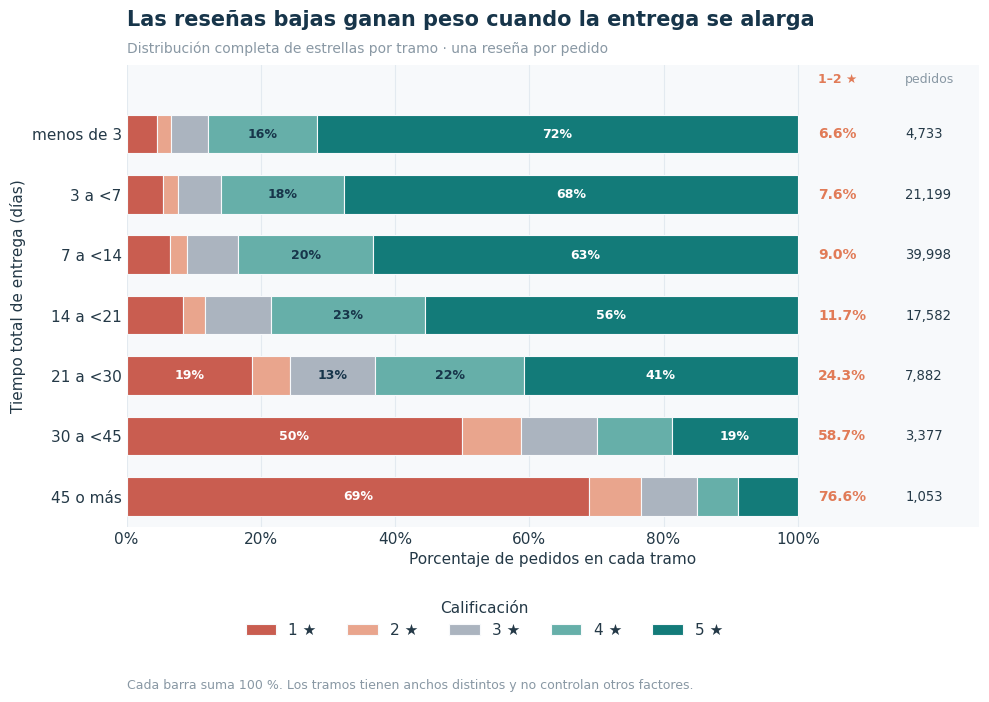

In [24]:
# Conteo de cada calificación (1-5) dentro de cada tramo de tiempo
conteo_estrellas = pd.crosstab(calificados["tramo_total"], calificados["review_score"])

# Normalizamos por fila para que cada tramo sume 100 %.
porcentaje_estrellas = conteo_estrellas.div(conteo_estrellas.sum(axis=1), axis=0) * 100
display(porcentaje_estrellas.round(1))

COLORES_ESTRELLAS = ["#C95D50", "#E9A58D", "#ABB4BF", "#66AFA9", "#137B79"]
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(porcentaje_estrellas))

# Vector acumulador de porcentajes
izquierda = np.zeros(len(y))

for estrellas_columna, color in zip(porcentaje_estrellas.columns, COLORES_ESTRELLAS):
    valores = porcentaje_estrellas[estrellas_columna].to_numpy()
    ax.barh(y, valores, left=izquierda, height=0.64, color=color,
            edgecolor=TEMA["fondo"], linewidth=0.8, label=f"{estrellas_columna:.0f} ★", zorder=3)
    # Solo rotulamos segmentos >= 12 % para evitar texto encimado.
    for fila, inicio, valor in zip(y, izquierda, valores):
        if valor >= 12:
            ax.text(inicio + valor / 2, fila, f"{valor:.0f}%", ha="center", va="center",
                    fontsize=9, fontweight="bold",
                    color="white" if estrellas_columna in (1, 5) else TEMA["azul"])
    # Desplazamos el origen izquierdo para la siguiente estrella.
    izquierda = izquierda + valores

# Columnas informativas a la derecha
for fila, tramo in zip(y, por_tramo.index):
    ax.text(103, fila, f"{por_tramo.loc[tramo, 'pct_baja']:.1f}%", va="center",
            fontsize=10, fontweight="bold", color=COLOR_TARDE)
    ax.text(116, fila, f"{por_tramo.loc[tramo, 'pedidos']:,.0f}", va="center", fontsize=9.5)
ax.text(103, -0.85, "1–2 ★", fontsize=9, fontweight="bold", color=COLOR_TARDE)
ax.text(116, -0.85, "pedidos", fontsize=9, color=TEMA["gris"])

ax.set_yticks(y, porcentaje_estrellas.index.astype(str))
ax.set_ylim(len(y) - 0.5, -1.15)
ax.set_xticks(range(0, 101, 20), [f"{valor}%" for valor in range(0, 101, 20)])
ax.set(
    xlim=(0, 127),
    title="Las reseñas bajas ganan peso cuando la entrega se alarga",
    xlabel="Porcentaje de pedidos en cada tramo",
    ylabel="Tiempo total de entrega (días)",
)
subtitulo(ax, "Distribución completa de estrellas por tramo · una reseña por pedido")
ax.grid(axis="x", zorder=0)
ax.legend(title="Calificación", ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.42, -0.13))
nota(ax, "Cada barra suma 100 %. Los tramos tienen anchos distintos y no controlan otros factores.", y=-0.33)
guardar_figura(fig, "figura_2_estrellas_por_tiempo.png")
plt.show()
plt.close(fig)

La calificación baja de forma continua conforme el pedido tarda más: la media pasa de **4.48 en los pedidos de menos de 3 días a 1.78 en los de 45 días o más**, y las reseñas bajas, de 6.6 % a 76.6 %. La correlación de Spearman es **−0.235**: negativa pero débil, porque la gran mayoría de los pedidos llega rápido y recibe 5 estrellas; la caída fuerte se concentra en la cola de pedidos lentos. El coeficiente prácticamente no cambia con otra regla de reseña (de −0.2345 a −0.2348).

**Figura 2. Qué muestra.** La distribución completa de estrellas en cada tramo, con el porcentaje de reseñas bajas y el número de pedidos a la derecha. En los pedidos de menos de 3 días, el 71.7 % da 5 estrellas y el 4.6 % da 1; en los de 45 días o más se invierte: el 68.9 % da 1 estrella y solo el 8.9 % da 5.

**Por qué importa.** La media resume en un número una escala ordinal. Ver las cinco estrellas confirma que el cambio no es un efecto del promedio: las reseñas de 1 estrella crecen y las de 5 se reducen de forma ordenada.

**Limitaciones.** Cada barra suma 100 %, así que el tamaño de cada tramo se anota aparte. Los cortes son una elección para describir, no umbrales, y los pedidos de cada tramo pueden diferir en producto, región o vendedor.

### 3.3 ¿Pesa la lentitud o la promesa incumplida?

Un pedido lento también tiene más probabilidad de llegar tarde, así que las dos cosas se mezclan. Para separarlas comparamos pedidos del **mismo tramo de tiempo total**, a tiempo contra tarde. Incluimos la mediana de días de cada grupo: dentro de un tramo, los pedidos tardíos podrían tardar algo más, y eso hay que tenerlo en cuenta.

In [25]:
tiempo_y_promesa = (
    calificados.groupby(["tramo_total", "tarde"], observed=True)
    .agg(
        pedidos=("review_score", "size"),
        mediana_dias=("total_dias", "median"),
        pct_baja=("calificacion_baja", "mean"),
    )
    .unstack("tarde")
)

tiempo_y_promesa.columns = [
    f"{medida}_{'tarde' if llego_tarde else 'a_tiempo'}" for medida, llego_tarde in tiempo_y_promesa.columns
]

# Convertimos proporciones a porcentajes y calculamos pp razón relativa
tiempo_y_promesa["pct_baja_a_tiempo"] *= 100
tiempo_y_promesa["pct_baja_tarde"] *= 100
tiempo_y_promesa["diferencia_pp"] = tiempo_y_promesa["pct_baja_tarde"] - tiempo_y_promesa["pct_baja_a_tiempo"]
tiempo_y_promesa["razon"] = tiempo_y_promesa["pct_baja_tarde"] / tiempo_y_promesa["pct_baja_a_tiempo"]
display(tiempo_y_promesa.round(2))

# Spearman entre duración y estrellas solo en pedidos a tiempo.
a_tiempo = calificados[~calificados["tarde"]]
rho_a_tiempo = a_tiempo[["total_dias", "review_score"]].corr(method="spearman").iloc[0, 1]
print(f"\n Spearman entre tiempo total y calificación, solo pedidos a tiempo: {rho_a_tiempo:.3f}")

,pedidos_a_tiempo,pedidos_tarde,mediana_dias_a_tiempo,mediana_dias_tarde,pct_baja_a_tiempo,pct_baja_tarde,diferencia_pp,razon
tramo_total,,,,,,,,
menos de 3,4733.0,NaN,2.17,NaN,6.63,NaN,NaN,NaN
3 a <7,21141.0,58.0,5.26,5.95,7.62,12.07,4.45,1.58
7 a <14,39685.0,313.0,9.95,10.91,8.77,32.59,23.81,3.71
14 a <21,17056.0,526.0,16.62,17.96,10.71,43.16,32.45,4.03
21 a <30,5873.0,2009.0,23.74,25.91,14.46,53.01,38.56,3.67
30 a <45,910.0,2467.0,32.88,35.83,21.21,72.56,51.35,3.42
45 o más,45.0,1008.0,48.95,52.52,33.33,78.57,45.24,2.36



 Spearman entre tiempo total y calificación, solo pedidos a tiempo: -0.127


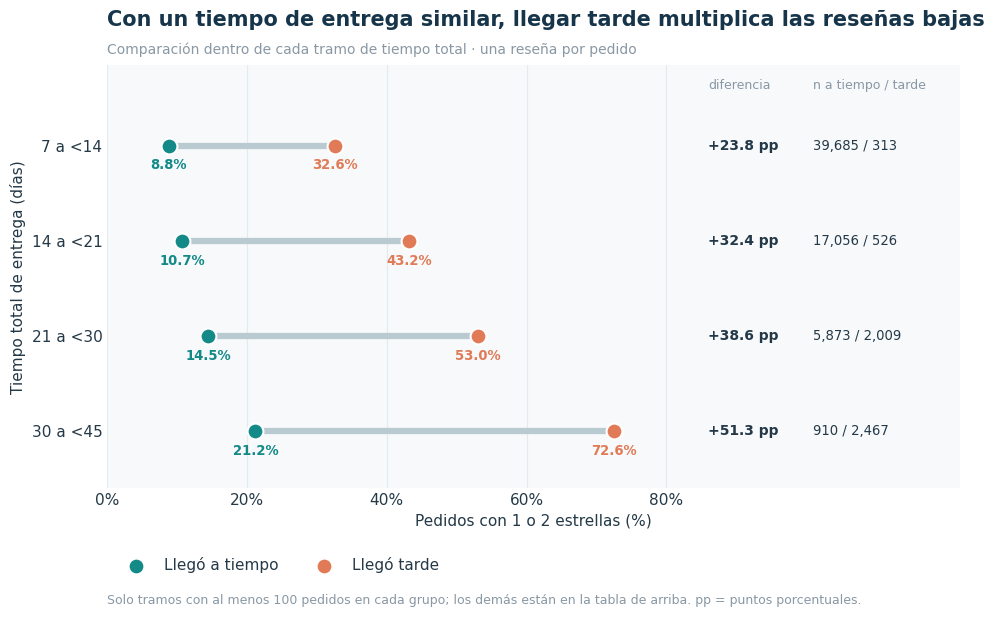

In [26]:
# Ploteamos tramos con >= 100 pedidos en ambos grupos (los tramos omitidos permanecen en la tabla)
pares = tiempo_y_promesa[
    tiempo_y_promesa["pedidos_a_tiempo"].ge(100) & tiempo_y_promesa["pedidos_tarde"].ge(100)
]

fig, ax = plt.subplots(figsize=(11, 5.5))
y = np.arange(len(pares))

# Dumbbell chart
ax.hlines(y, pares["pct_baja_a_tiempo"].to_numpy(), pares["pct_baja_tarde"].to_numpy(),
          color="#B9CAD1", linewidth=4.5, zorder=2)
ax.scatter(pares["pct_baja_a_tiempo"], y, s=130, color=COLOR_A_TIEMPO,
           edgecolor="white", linewidth=1.5, zorder=3, label="Llegó a tiempo")
ax.scatter(pares["pct_baja_tarde"], y, s=130, color=COLOR_TARDE,
           edgecolor="white", linewidth=1.5, zorder=3, label="Llegó tarde")

#Configuración de etiquetas
for fila, tramo in zip(y, pares.index):
    a_tiempo_pct = pares.loc[tramo, "pct_baja_a_tiempo"]
    tarde_pct = pares.loc[tramo, "pct_baja_tarde"]
    ax.annotate(f"{a_tiempo_pct:.1f}%", (a_tiempo_pct, fila), xytext=(0, -17), textcoords="offset points",
                ha="center", fontsize=9.5, fontweight="bold", color=COLOR_A_TIEMPO)
    ax.annotate(f"{tarde_pct:.1f}%", (tarde_pct, fila), xytext=(0, -17), textcoords="offset points",
                ha="center", fontsize=9.5, fontweight="bold", color=COLOR_TARDE)
    ax.text(86, fila, f"+{pares.loc[tramo, 'diferencia_pp']:.1f} pp", va="center",
            fontsize=10, fontweight="bold")
    ax.text(101, fila, f"{pares.loc[tramo, 'pedidos_a_tiempo']:,.0f} / {pares.loc[tramo, 'pedidos_tarde']:,.0f}",
            va="center", fontsize=9.5)
ax.text(86, -0.6, "diferencia", fontsize=9, color=TEMA["gris"])
ax.text(101, -0.6, "n a tiempo / tarde", fontsize=9, color=TEMA["gris"])

ax.set_yticks(y, pares.index.astype(str))
ax.set_ylim(len(pares) - 0.4, -0.85)
ax.set_xticks(range(0, 81, 20), [f"{valor}%" for valor in range(0, 81, 20)])
ax.set(
    xlim=(0, 122),
    title="Con un tiempo de entrega similar, llegar tarde multiplica las reseñas bajas",
    xlabel="Pedidos con 1 o 2 estrellas (%)",
    ylabel="Tiempo total de entrega (días)",
)
subtitulo(ax, "Comparación dentro de cada tramo de tiempo total · una reseña por pedido")
ax.grid(axis="x", zorder=0)
ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.13))
nota(ax, "Solo tramos con al menos 100 pedidos en cada grupo; los demás están en la tabla de arriba. "
         "pp = puntos porcentuales.", y=-0.25)
guardar_figura(fig, "figura_3_puntualidad_mismo_tiempo.png")
plt.show()
plt.close(fig)

**Figura 3. Qué muestra.** Para cada tramo de tiempo total, el porcentaje de reseñas bajas de los pedidos que llegaron a tiempo (turquesa) y de los que llegaron tarde (coral). Entre 21 y 30 días, por ejemplo, 14.5 % a tiempo contra 53.0 % tarde.

**Por qué importa.** Con un tiempo de entrega similar, los pedidos tardíos tienen **entre 24 y 51 pp más** de reseñas bajas, es decir, **entre 3.4 y 4 veces** la proporción de los puntuales. La lentitud por sí sola también pesa, pero menos: entre los pedidos a tiempo, las reseñas bajas suben de 8.8 % en el tramo de 7 a 14 días a 21.2 % en el de 30 a 45 (Spearman de −0.127 entre tiempo y calificación, solo con pedidos a tiempo).

**Limitaciones.** Solo se grafican los tramos con al menos 100 pedidos en cada grupo: quedan fuera el de 3 a 7 días (58 pedidos tardíos), el de 45 o más (45 pedidos a tiempo) y el de menos de 3 días, donde ningún pedido llegó tarde; todos siguen en la tabla. Dentro de cada tramo, los tardíos tardan entre 1 y 3 días más (mediana), así que la comparación no es exacta; por eso la repetimos con tramos de un día. Otros factores (producto, vendedor, región) no están controlados.

### 3.4 Comprobación con tramos de 24 horas

Un tramo como "21 a <30" reúne pedidos de 21.1 y de 29.8 días. Para que los grupos sean más parecidos, dividimos el tiempo total en **tramos de un día** (`np.floor`): el tramo 14 contiene los pedidos que tardaron de 14 a menos de 15 días. En cada uno calculamos la diferencia de reseñas bajas, tarde menos a tiempo. Solo usamos los días con al menos 30 pedidos en cada grupo, para no basar la comparación en grupos diminutos.

In [27]:
# Bloque exacto de 24 horas redondeando hacia abajo:
calificados["dia_entrega"] = np.floor(calificados["total_dias"]).astype(int)

# Agrupamos por día exacto y puntualidad
por_dia = (
    calificados.groupby(["dia_entrega", "tarde"])
    .agg(pedidos=("review_score", "size"), pct_baja=("calificacion_baja", "mean"))
    .unstack("tarde")
)

# >= 30 pedidos en cada grupo.
MIN_POR_GRUPO = 30
comparables = por_dia[
    por_dia[("pedidos", False)].ge(MIN_POR_GRUPO) & por_dia[("pedidos", True)].ge(MIN_POR_GRUPO)
]

# Brecha diaria en puntos porcentuales: % bajas en tardíos menos % bajas en puntuales.
brecha_dia = (comparables[("pct_baja", True)] - comparables[("pct_baja", False)]) * 100

print(f"Días comparables: {len(brecha_dia)} (del día {brecha_dia.index.min()} al {brecha_dia.index.max()})")
print(f"Días donde los tardíos tienen más reseñas bajas: {brecha_dia.gt(0).sum()} de {len(brecha_dia)}")
print(f"Diferencia: mínima {brecha_dia.min():.1f} pp, mediana {brecha_dia.median():.1f} pp, "
      f"máxima {brecha_dia.max():.1f} pp (día {brecha_dia.idxmax()})")

Días comparables: 31 (del día 7 al 37)
Días donde los tardíos tienen más reseñas bajas: 31 de 31
Diferencia: mínima 15.9 pp, mediana 33.9 pp, máxima 54.5 pp (día 30)


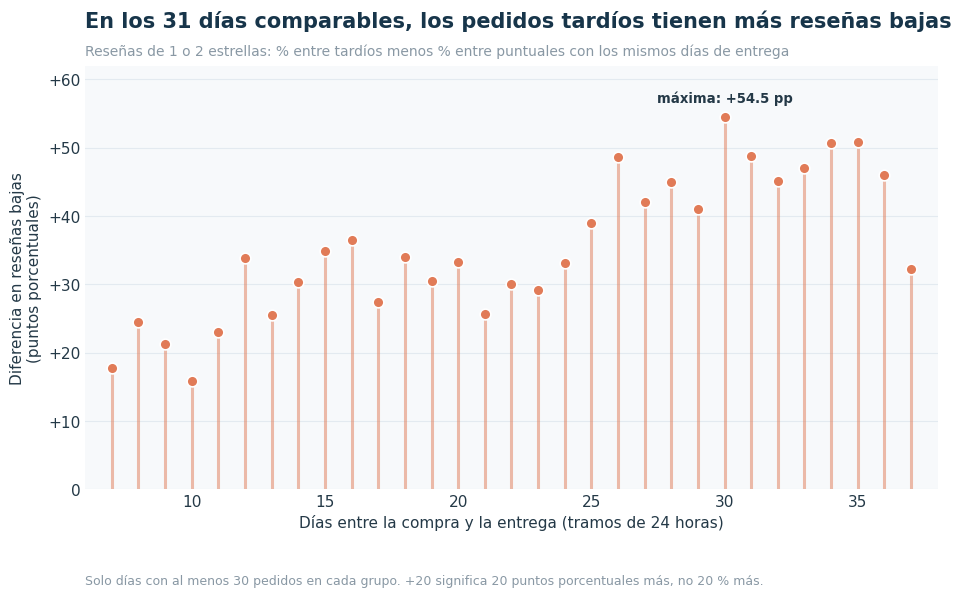

In [43]:
# Gráfico lollipop con la brecha diaria de reseñas bajas
fig, ax = plt.subplots(figsize=(11, 5.5))
dias = brecha_dia.index.to_numpy()
ax.vlines(dias, 0, brecha_dia.to_numpy(), color=COLOR_TARDE, alpha=0.5, linewidth=2.2, zorder=2)
ax.scatter(dias, brecha_dia, s=60, color=COLOR_TARDE, edgecolor="white", linewidth=1.2, zorder=3)
dia_maximo = brecha_dia.idxmax()
ax.annotate(f"máxima: +{brecha_dia.max():.1f} pp", (dia_maximo, brecha_dia.max()),
            xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold")

ax.set(
    xlim=(dias.min()-1, dias.max() + 1),
    ylim=(0, 62),
    title=f"En los {len(brecha_dia)} días comparables, los pedidos tardíos tienen más reseñas bajas",
    xlabel="Días entre la compra y la entrega (tramos de 24 horas)",
    ylabel="Diferencia en reseñas bajas\n(puntos porcentuales)",
)
subtitulo(ax, "Reseñas de 1 o 2 estrellas: % entre tardíos menos % entre puntuales con los mismos días de entrega")
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"+{valor:.0f}" if valor > 0 else "0"))
ax.grid(axis="y", zorder=0)
nota(ax, f"Solo días con al menos {MIN_POR_GRUPO} pedidos en cada grupo. +20 significa 20 puntos porcentuales más, "
         "no 20 % más.")
guardar_figura(fig, "figura_4_brecha_por_dia.png")
plt.show()
plt.close(fig)

**Figura 4. Qué muestra.** Cada punto es un día de entrega, del 7 al 37; su altura es cuántos puntos porcentuales más de reseñas bajas tienen los pedidos tardíos que los puntuales que tardaron los mismos días.

**Por qué importa.** La diferencia es positiva en **los 31 días**: va de +15.9 a +54.5 pp, con mediana de +33.9 pp. El resultado de la figura 3 no depende de los tramos amplios: incluso con el mismo número de días, llegar tarde se asocia con muchas más reseñas bajas.

**Limitaciones.** Igualar los días de entrega no iguala producto, vendedor ni región. El mínimo de 30 pedidos por grupo es una regla para leer la figura, no una prueba estadística; fuera de los días 7 a 37 hay muy pocos pedidos en alguno de los dos grupos.

### 3.5 Días respecto de la fecha prometida

Ahora agrupamos por cuántos días antes o después de la fecha prometida llegó el pedido, y repetimos el cálculo sin las respuestas dadas antes de la entrega (decisión 7).

In [29]:
cortes_promesa = [-np.inf, -10, -5, 0, 5, 10, np.inf]
etiquetas_promesa = ["10 o más antes", "5 a 9 antes", "0 a 4 antes",
                     "1 a 5 tarde", "6 a 10 tarde", "más de 10 tarde"]
calificados["tramo_promesa"] = pd.cut(
    calificados["dias_tarde"], bins=cortes_promesa, labels=etiquetas_promesa
)

por_promesa = resumen_por(calificados, "tramo_promesa")
por_promesa_sin_previas = resumen_por(calificados[~calificados["respuesta_antes_entrega"]], "tramo_promesa")
display(pd.concat(
    {"todas las respuestas": por_promesa, "sin respuestas previas a la entrega": por_promesa_sin_previas},
    axis=1,
))

todas las respuestas                 \
                             pedidos media pct_baja   
tramo_promesa                                         
10 o más antes                 61523  4.32     8.89   
5 a 9 antes                    20032  4.26     9.60   
0 a 4 antes                     7888  4.12    11.37   
1 a 5 tarde                     2722  2.99    41.15   
6 a 10 tarde                    1634  1.77    77.48   
más de 10 tarde                 2025  1.71    78.86   

                sin respuestas previas a la entrega                 
                                            pedidos media pct_baja  
tramo_promesa                                                       
10 o más antes                                61419  4.32     8.88  
5 a 9 antes                                   19985  4.26     9.59  
0 a 4 antes                                    7859  4.12    11.31  
1 a 5 tarde                                    1723  3.74    18.80  
6 a 10 tarde                                    149  3.62    20.81  
más de 10 tarde                                  36  2.97    44.44

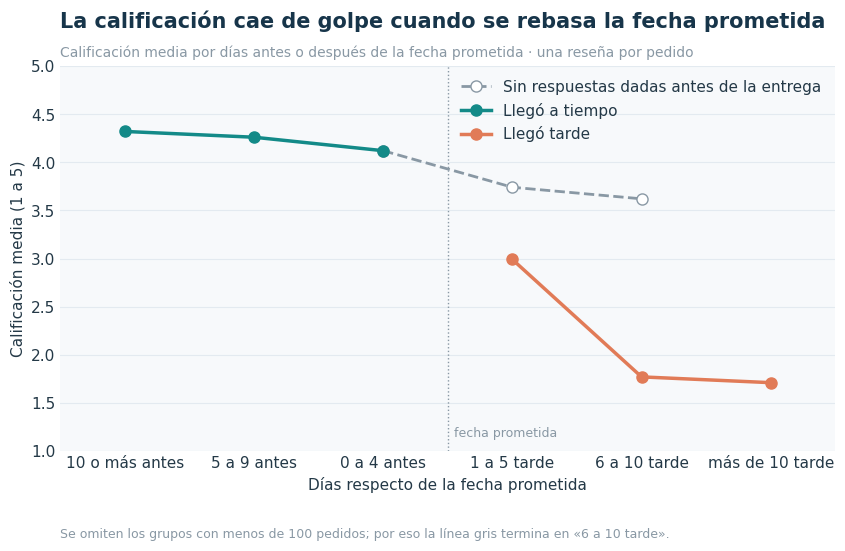

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))

# Separación de tramos antes/después de la promesa y serie de sensibilidad (>= 100 pedidos)
antes_de_la_promesa = por_promesa.iloc[:3]
despues_de_la_promesa = por_promesa.iloc[3:]
# Antes de la promesa las dos versiones coinciden: la gris arranca en el último punto a tiempo.
sin_previas = por_promesa_sin_previas[por_promesa_sin_previas["pedidos"] >= 100].iloc[2:]

# Gráfica de líneas (principal vs. sensibilidad) y umbral vertical de la fecha prometida
ax.plot(sin_previas.index.codes, sin_previas["media"], marker="o", markersize=8, linewidth=2,
        linestyle="--", color=TEMA["gris"], markerfacecolor="white",
        label="Sin respuestas dadas antes de la entrega")
ax.plot(antes_de_la_promesa.index.codes, antes_de_la_promesa["media"], marker="o", markersize=8,
        linewidth=2.5, color=COLOR_A_TIEMPO, label="Llegó a tiempo", zorder=3)
ax.plot(despues_de_la_promesa.index.codes, despues_de_la_promesa["media"], marker="o", markersize=8,
        linewidth=2.5, color=COLOR_TARDE, label="Llegó tarde", zorder=3)
ax.axvline(2.5, color=TEMA["gris"], linestyle=":", linewidth=1)
ax.text(2.55, 1.15, "fecha prometida", color=TEMA["gris"], fontsize=9)

# Configuración de ejes, títulos, cuadrícula y leyenda
ax.set_xticks(range(len(etiquetas_promesa)), etiquetas_promesa)
ax.set(
    ylim=(1, 5),
    xlim=(-0.5, len(etiquetas_promesa) - 0.5),
    title="La calificación cae de golpe cuando se rebasa la fecha prometida",
    xlabel="Días respecto de la fecha prometida",
    ylabel="Calificación media (1 a 5)",
)
subtitulo(ax, "Calificación media por días antes o después de la fecha prometida · una reseña por pedido")
ax.grid(axis="y", zorder=0)
ax.legend(frameon=False, loc="upper right")
nota(ax, "Se omiten los grupos con menos de 100 pedidos; por eso la línea gris termina en «6 a 10 tarde».")
guardar_figura(fig, "figura_5_promesa_y_calificacion.png")
plt.show()
plt.close(fig)

**Figura 5. Qué muestra.** Mientras el pedido llega antes de la fecha prometida, la calificación casi no cambia: 4.32 si llega 10 días antes o más y 4.12 si llega entre 0 y 4 días antes. Al rebasar la fecha, cae a **2.99 con 1 a 5 días de retraso** y a cerca de 1.7 con más de 5 días.

**Por qué importa.** La satisfacción depende menos de cuánto tarda el pedido que de si se cumple lo prometido: la fecha prometida funciona como un umbral.

**Limitaciones.** Gran parte de la caída viene de respuestas dadas durante la espera. Sin ellas (línea gris), el escalón es mucho menor: 3.74 con 1 a 5 días de retraso y 3.62 con 6 a 10. Con más de 10 días de retraso, solo 36 de 2,025 clientes respondieron después de recibir el pedido, así que ese grupo no se grafica. Como se ve en la sección 2.6, a esos clientes la encuesta les llegó mientras todavía esperaban.

### 3.6 ¿Cuándo respondió el cliente?

Cruzamos la puntualidad con el momento de la respuesta para ver dónde se concentran las calificaciones bajas. "Antes" significa que la respuesta se registró antes de la hora de entrega registrada; "al recibir o después" incluye respuestas simultáneas o posteriores.

In [31]:
# Cruce de puntualidad con momento de respuesta
momento = (
    calificados.groupby(["tarde", "respuesta_antes_entrega"])
    .agg(
        pedidos=("review_score", "size"),
        media=("review_score", "mean"),
        pct_baja=("calificacion_baja", "mean"),
    )
)

# Conversión a porcentaje y etiquetas legibles para el índice
momento["pct_baja"] = momento["pct_baja"] * 100
momento.index = [
    f"{'Tarde' if llego_tarde else 'A tiempo'} · respondió {'antes de recibirlo' if antes else 'al recibirlo o después'}"
    for llego_tarde, antes in momento.index
]
display(momento.round(2))

,pedidos,media,pct_baja
A tiempo · respondió al recibirlo o después,89263,4.29,9.25
A tiempo · respondió antes de recibirlo,180,3.96,17.22
Tarde · respondió al recibirlo o después,1908,3.72,19.44
Tarde · respondió antes de recibirlo,4473,1.65,80.75


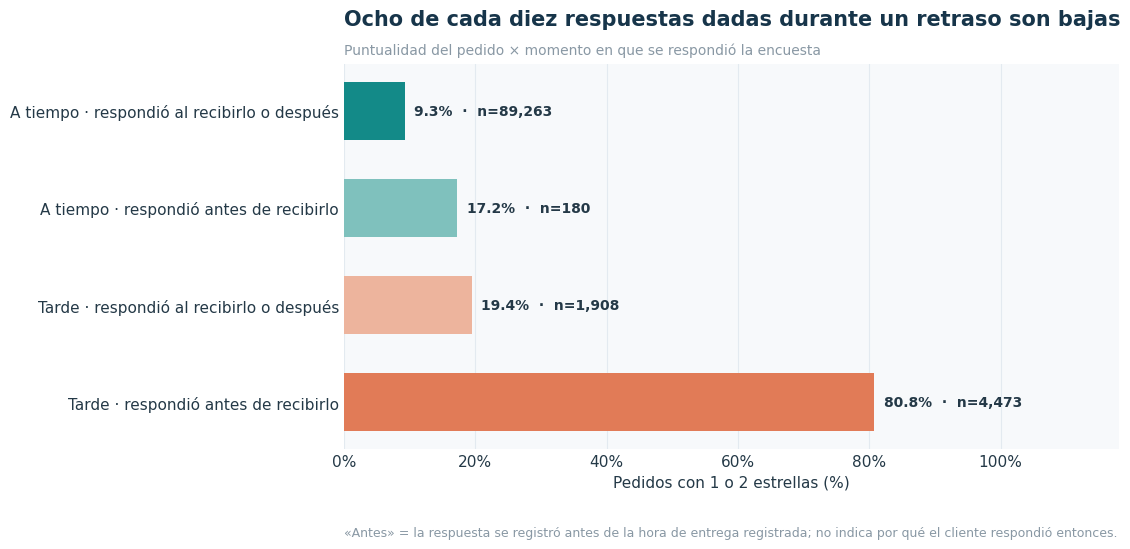

In [32]:
# Paleta de colores y gráfico de barras horizontales por subgrupo
colores_momento = [COLOR_A_TIEMPO, "#7FC1BD", "#EDB49D", COLOR_TARDE]

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(momento))
ax.barh(y, momento["pct_baja"], color=colores_momento, height=0.6, zorder=3)

# Etiquetas con porcentaje de reseñas bajas y tamaño de muestra (n)
for fila, (porcentaje, pedidos_grupo) in enumerate(zip(momento["pct_baja"], momento["pedidos"])):
    ax.text(porcentaje + 1.5, fila, f"{porcentaje:.1f}%  ·  n={pedidos_grupo:,}",
            va="center", fontsize=10, fontweight="bold")

# Configuración de ejes, títulos y cuadrícula
ax.set_yticks(y, momento.index)
ax.invert_yaxis()
ax.set_xticks(range(0, 101, 20), [f"{valor}%" for valor in range(0, 101, 20)])
ax.set(
    xlim=(0, 118),
    title="Ocho de cada diez respuestas dadas durante un retraso son bajas",
    xlabel="Pedidos con 1 o 2 estrellas (%)",
)
subtitulo(ax, "Puntualidad del pedido × momento en que se respondió la encuesta")
ax.grid(axis="x", zorder=0)
nota(ax, "«Antes» = la respuesta se registró antes de la hora de entrega registrada; no indica por qué el cliente "
         "respondió entonces.")
guardar_figura(fig, "figura_6_momento_de_la_respuesta.png")
plt.show()
plt.close(fig)

**Figura 6. Qué muestra.** El porcentaje de reseñas bajas en cuatro grupos: a tiempo o tarde, y respuesta antes o después de recibir el pedido. Cuando el pedido llegó tarde y el cliente respondió **antes de recibirlo**, el **80.8 %** de las reseñas son bajas (4,473 pedidos); si respondió al recibirlo o después, el 19.4 % (1,908 pedidos).

**Por qué importa.** El castigo más fuerte al retraso aparece mientras el cliente todavía espera, y ese es el caso más común: 7 de cada 10 pedidos tardíos se calificaron antes de llegar. Aun así, un pedido tardío calificado después de recibirlo tiene el doble de reseñas bajas que uno a tiempo (19.4 % contra 9.3 %).

**Limitaciones.** "Antes" compara dos registros administrativos (la hora de respuesta y la de entrega); no sabemos por qué el cliente respondió en ese momento. El grupo de pedidos a tiempo con respuesta previa es muy pequeño (180 pedidos).

### 3.7 Sensibilidad: ¿y si solo usamos respuestas dadas al recibir el pedido o después?

Una forma de "aislar" la opinión sobre el pedido recibido es quitar las respuestas previas a la entrega. Repetimos la comparación de la figura 3 con esa submuestra, con los mismos tramos, y medimos cuántos pedidos tardíos sobreviven al filtro. Es un **análisis de sensibilidad**, no una corrección: no hay evidencia de que esas respuestas sean errores, y quitarlas cambia qué pedidos se comparan.

In [33]:
# Solo respuestas registradas al recibir el pedido o después
posteriores = calificados[~calificados["respuesta_antes_entrega"]]


# Función auxiliar para calcular tamaños de grupo y brecha (tarde − a tiempo) por tramo
def brecha_por_tramo(tabla):
    """Pedidos por grupo y diferencia de reseñas bajas (tarde − a tiempo) por tramo de tiempo total."""
    grupos = (
        tabla.groupby(["tramo_total", "tarde"], observed=True)
        .agg(pedidos=("review_score", "size"), pct_baja=("calificacion_baja", "mean"))
        .unstack("tarde")
    )
    return pd.DataFrame({
        "pedidos_a_tiempo": grupos[("pedidos", False)],
        "pedidos_tarde": grupos[("pedidos", True)],
        "diferencia_pp": (grupos[("pct_baja", True)] - grupos[("pct_baja", False)]) * 100,
    })


# Comparación lado a lado entre todas las respuestas y solo las posteriores
filtro = brecha_por_tramo(calificados).join(
    brecha_por_tramo(posteriores), lsuffix="_todas", rsuffix="_posteriores"
)
filtro["tardes_conservados_pct"] = filtro["pedidos_tarde_posteriores"] / filtro["pedidos_tarde_todas"] * 100
display(filtro.round(2))

# Qué cantidad se conserva de cada grupo y qué tipo de retrasos sobreviven
conservados_a_tiempo = (~posteriores["tarde"]).sum() / (~calificados["tarde"]).sum()
conservados_tarde = posteriores["tarde"].sum() / calificados["tarde"].sum()
print(f"\n El filtro conserva {conservados_a_tiempo:.1%} de los pedidos a tiempo y {conservados_tarde:.1%} de los tardíos.")
tardios_conservados = posteriores[posteriores["tarde"]]
print(f"Tardíos con 1 a 5 días de retraso: {tardios_conservados['dias_tarde'].le(5).mean():.1%} de los conservados, "
      f"{calificados.loc[calificados['tarde'], 'dias_tarde'].le(5).mean():.1%} de todos los tardíos.")

,pedidos_a_tiempo_todas,pedidos_tarde_todas,diferencia_pp_todas,pedidos_a_tiempo_posteriores,pedidos_tarde_posteriores,diferencia_pp_posteriores,tardes_conservados_pct
tramo_total,,,,,,,
menos de 3,4733.0,NaN,NaN,4733.0,NaN,NaN,NaN
3 a <7,21141.0,58.0,4.45,21135.0,52.0,0.07,89.66
7 a <14,39685.0,313.0,23.81,39628.0,208.0,3.25,66.45
14 a <21,17056.0,526.0,32.45,16994.0,313.0,6.24,59.51
21 a <30,5873.0,2009.0,38.56,5832.0,907.0,5.55,45.15
30 a <45,910.0,2467.0,51.35,898.0,402.0,2.95,16.30
45 o más,45.0,1008.0,45.24,43.0,26.0,13.60,2.58



 El filtro conserva 99.8% de los pedidos a tiempo y 29.9% de los tardíos.
Tardíos con 1 a 5 días de retraso: 90.3% de los conservados, 42.7% de todos los tardíos.


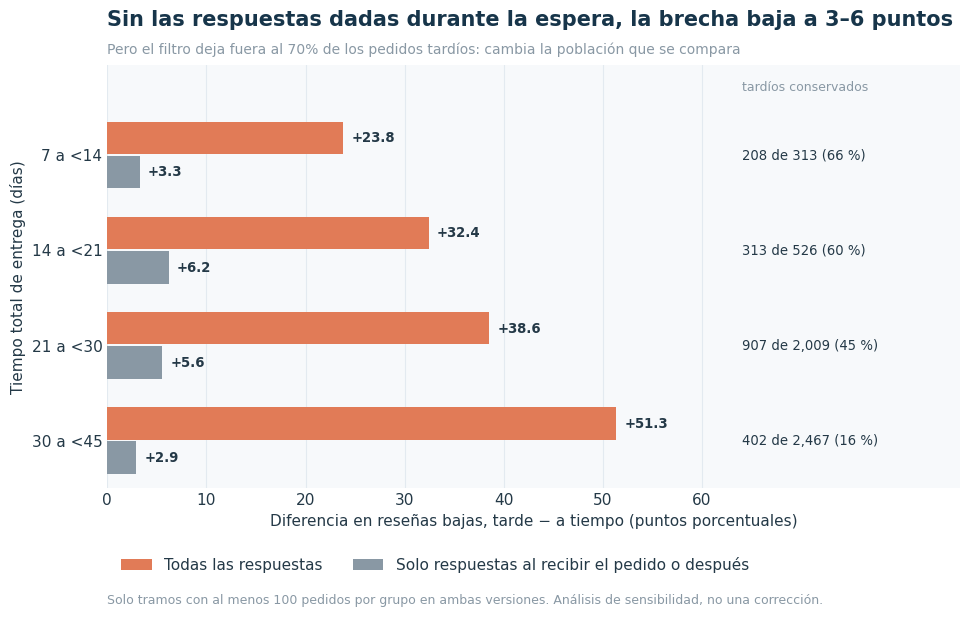

In [34]:
# Filtrado de tramos con al menos 100 pedidos por grupo en ambas versiones
columnas_n = ["pedidos_a_tiempo_todas", "pedidos_tarde_todas", "pedidos_a_tiempo_posteriores", "pedidos_tarde_posteriores"]
visibles = filtro[filtro[columnas_n].ge(100).all(axis=1)]

# Gráfico de barras horizontales: todas las respuestas vs solo posteriores
fig, ax = plt.subplots(figsize=(11, 5.5))
y = np.arange(len(visibles))
ax.barh(y - 0.18, visibles["diferencia_pp_todas"], height=0.34, color=COLOR_TARDE,
        label="Todas las respuestas", zorder=3)
ax.barh(y + 0.18, visibles["diferencia_pp_posteriores"], height=0.34, color=TEMA["gris"],
        label="Solo respuestas al recibir el pedido o después", zorder=3)

# Etiquetas de pp y columna informativa con tardíos conservados tras el filtro
for fila, tramo in zip(y, visibles.index):
    for desplazamiento, columna in [(-0.18, "diferencia_pp_todas"), (0.18, "diferencia_pp_posteriores")]:
        valor = visibles.loc[tramo, columna]
        ax.text(valor + 0.8, fila + desplazamiento, f"+{valor:.1f}", va="center", fontsize=9.5, fontweight="bold")
    ax.text(64, fila, f"{visibles.loc[tramo, 'pedidos_tarde_posteriores']:,.0f} de "
                      f"{visibles.loc[tramo, 'pedidos_tarde_todas']:,.0f} "
                      f"({visibles.loc[tramo, 'tardes_conservados_pct']:.0f} %)", va="center", fontsize=9.5)
ax.text(64, -0.68, "tardíos conservados", fontsize=9, color=TEMA["gris"])

# Configuracón del plot
minimo, maximo = visibles["diferencia_pp_posteriores"].min(), visibles["diferencia_pp_posteriores"].max()
ax.set_yticks(y, visibles.index.astype(str))
ax.set_ylim(len(y) - 0.5, -0.95)
ax.set_xticks(range(0, 61, 10))
ax.set(
    xlim=(0, 86),
    title=f"Sin las respuestas dadas durante la espera, la brecha baja a {minimo:.0f}–{maximo:.0f} puntos",
    xlabel="Diferencia en reseñas bajas, tarde − a tiempo (puntos porcentuales)",
    ylabel="Tiempo total de entrega (días)",
)
subtitulo(ax, f"Pero el filtro deja fuera al {1 - conservados_tarde:.0%} de los pedidos tardíos: "
              "cambia la población que se compara")
ax.grid(axis="x", zorder=0)
ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.13))
nota(ax, "Solo tramos con al menos 100 pedidos por grupo en ambas versiones. Análisis de sensibilidad, "
         "no una corrección.", y=-0.25)
guardar_figura(fig, "figura_7_filtro_temporal.png")
plt.show()
plt.close(fig)

**Figura 7. Qué muestra.** Para cada tramo de tiempo total, la diferencia de reseñas bajas entre tardíos y puntuales con todas las respuestas (coral) y solo con las dadas al recibir el pedido o después (gris). A la derecha, cuántos pedidos tardíos conserva el filtro.

**Por qué importa.** Sin las respuestas dadas durante la espera, la diferencia baja de 24–51 pp a **3–6 pp**. Pero no podemos concluir que "después de recibirlo, el retraso casi no importa": el filtro conserva el 99.8 % de los pedidos a tiempo y solo el **29.9 % de los tardíos**, y los que quedan son sobre todo retrasos cortos (90.3 % de 1 a 5 días, contra 42.7 % entre todos los tardíos). En el tramo de 30 a 45 días sobrevive solo el 16 %. Las dos versiones comparan poblaciones distintas.

**Limitaciones.** No sabemos cómo habrían calificado después de la entrega los clientes que respondieron antes. Por eso el análisis principal conserva todas las respuestas y esta figura se lee como una comprobación de cuánto depende el resultado del momento de la respuesta.

### 3.8 Respuesta a la pregunta 1

- **Sí hay relación:** a mayor tiempo de entrega, menor satisfacción. La calificación media baja de 4.48 (menos de 3 días) a 1.78 (45 días o más) y las reseñas bajas pasan de 6.6 % a 76.6 %. La correlación global es débil (Spearman de −0.235) porque la mayoría de los pedidos llega rápido y bien calificado, y no depende de la regla para elegir la reseña.
- **Lo que más se asocia con la insatisfacción es incumplir la fecha prometida.** Con un tiempo de entrega similar, los pedidos tardíos tienen entre 3.4 y 4 veces más reseñas bajas (de +24 a +51 pp), y la diferencia aparece en los 31 días de entrega comparables. La calificación cae de golpe al rebasar la fecha prometida. Entre los pedidos a tiempo, la lentitud pesa menos (Spearman de −0.127).
- **Ese comportamiento se observa sobre todo mientras el cliente espera.** Cuando un pedido se retrasa, se envía la encuesta 2 días después de la fecha prometida aunque el pedido no haya llegado; el 70 % de los clientes con pedido tardío respondió antes de recibirlo y el 80.8 % de ellos dio 1 o 2 estrellas. Entre quienes respondieron después de recibirlo, la diferencia con los puntuales es mucho menor, pero esa comparación deja fuera a la mayoría de los tardíos y conserva sobre todo retrasos cortos.

Esta es una asociación descriptiva entre pedidos entregados con reseña; no demuestra que el retraso cause la baja calificación.

## 4. Pregunta 2 · Volumen mensual de pedidos y retrasos

*¿Existe una asociación entre los meses de mayor volumen de pedidos y el incremento en los retrasos de entrega?*

Cambiamos de unidad: ahora **cada observación es un mes de compra**, no un pedido. Para cada mes $m$ calculamos:

$$\text{volumen}_m = \#\{\text{pedidos comprados en } m\}, \qquad \text{retraso}_m = 100\cdot\frac{\#\{\text{entregados de } m \text{ que llegaron tarde}\}}{\#\{\text{entregados de } m\}}, \qquad \text{cobertura}_m = 100\cdot\frac{\#\{\text{entregados de } m\}}{\text{volumen}_m}.$$

- El **volumen** cuenta todos los pedidos comprados en el mes, en cualquier estado, porque todos representan carga para la operación.
- El **retraso** solo puede medirse en los pedidos entregados (decisión 4). Dividir entre todos los pedidos contaría como puntuales a los que nunca llegaron.
- La **cobertura** indica qué parte de los pedidos del mes entra en el cálculo del retraso.

### 4.1 Pedidos y retrasos por mes

In [35]:
# Volumen total de pedidos comprados por mes (incluye todos los estados)
mes_compra = pedidos["order_purchase_timestamp"].dt.to_period("M")
volumen = pedidos.groupby(mes_compra).size().rename("pedidos")

# Pedidos entregados y retrasados por mes de compra
retrasos = entregados.groupby(entregados["order_purchase_timestamp"].dt.to_period("M")).agg(
    entregados=("order_id", "size"),
    tardes=("tarde", "sum"),
)

# Tabla mensual combinada: % de retraso (sobre entregados) y % de cobertura (entregados sobre total)
mensual = volumen.to_frame().join(retrasos).fillna(0).astype(int)
mensual["pct_tarde"] = mensual["tardes"] / mensual["entregados"] * 100
mensual["cobertura"] = mensual["entregados"] / mensual["pedidos"] * 100
mensual.index.name = "mes_compra"
display(mensual.round(2))  # se redondea solo al mostrar

# Top 3 días individuales con mayor volumen de pedidos
print("Días con más pedidos:")
display(pedidos["order_purchase_timestamp"].dt.date.value_counts().head(3).to_frame("pedidos"))

,pedidos,entregados,tardes,pct_tarde,cobertura
mes_compra,,,,,
2016-09,4,1,1,100.00,25.00
2016-10,324,265,2,0.75,81.79
2016-12,1,1,0,0.00,100.00
2017-01,800,750,22,2.93,93.75
2017-02,1780,1653,49,2.96,92.87
2017-03,2682,2546,116,4.56,94.93
2017-04,2404,2303,151,6.56,95.80
2017-05,3700,3545,106,2.99,95.81
2017-06,3245,3135,95,3.03,96.61


Días con más pedidos:


,pedidos
order_purchase_timestamp,
2017-11-24,1176
2017-11-25,499
2017-11-27,403


**Lo que muestra la tabla**

- Los extremos del registro están incompletos: 2016 tiene meses con 4, 324 y 1 pedidos (y ninguno en noviembre), y los últimos meses (septiembre y octubre de 2018) tienen 16 y 4 pedidos, ninguno entregado, porque los datos terminan el 17 de octubre de 2018.
- Entre enero de 2017 y agosto de 2018 hay **20 meses consecutivos**, todos con al menos 800 pedidos y una cobertura de entre 92.9 % y 98.9 %.
- Al final de ese periodo no se ve que falten pedidos todavía en camino: la cobertura de junio a agosto de 2018 (97.5 % a 98.9 %) no es menor que la de los meses anteriores. Si lo fuera, el retraso de esos meses estaría subestimado, porque los pedidos tardíos aún en camino no aparecerían como entregados.
- El día con más pedidos fue el **24 de noviembre de 2017**, el Black Friday de ese año.

**Decisión 8.** Analizamos de enero de 2017 a agosto de 2018. Los meses de los extremos tienen muy pocos pedidos y su porcentaje de retraso no sería comparable.

In [36]:
# De enero del 2017 a agosto de 2018
periodo = mensual.loc["2017-01":"2018-08"].copy()
assert periodo.index.equals(pd.period_range("2017-01", "2018-08", freq="M")), "Faltan meses en el periodo."
print("Meses analizados:", len(periodo))
print("Pedidos por mes: mínimo", periodo["pedidos"].min(), "y máximo", periodo["pedidos"].max())
print(f"Cobertura: de {periodo['cobertura'].min():.2f} % a {periodo['cobertura'].max():.2f} %")

# Registro de decisión 8
registrar_decision(
    "Decisión 8", "orders", "meses incompletos al inicio (2016) y al final (sep-oct 2018)",
    mensual["pedidos"].sum() - periodo["pedidos"].sum(),
    "analizar de enero 2017 a agosto 2018 (20 meses)",
    "solo hay un noviembre y un periodo de 20 meses",
)

Meses analizados: 20
Pedidos por mes: mínimo 800 y máximo 7544
Cobertura: de 92.87 % a 98.85 %


### 4.2 ¿Los meses con más pedidos tienen más retrasos?

Medimos la asociación de cuatro formas:

1. La correlación de Spearman entre pedidos y porcentaje de retraso de cada mes (**niveles**).
2. El retraso de los 5 meses con más pedidos contra el resto.
3. La correlación entre los **cambios** de un mes a otro, $\Delta x_m = x_m - x_{m-1}$. Responde otra pregunta: si cuando el volumen sube de un mes al siguiente, el retraso también sube. Pierde una observación (19 cambios).
4. La correlación de niveles quitando **un mes a la vez**, para ver si un solo mes la determina.

Con 20 meses, estos resultados son únicamente exploratorios.

In [37]:
# Correlación de Spearman entre volumen mensual y porcentaje de retrasos
rho_mensual = periodo[["pedidos", "pct_tarde"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman entre pedidos del mes y % de retrasos ({len(periodo)} meses): {rho_mensual:.3f}")

# Comparación del % de retraso entre los 5 meses de mayor volumen y el resto del periodo
mas_volumen = periodo["pedidos"].nlargest(5).index
resto = periodo.drop(mas_volumen)
comparacion = pd.DataFrame({
    "meses": [len(mas_volumen), len(resto)],
    "pct_tarde": [
        periodo.loc[mas_volumen, "tardes"].sum() / periodo.loc[mas_volumen, "entregados"].sum() * 100,
        resto["tardes"].sum() / resto["entregados"].sum() * 100,
    ],
}, index=["5 meses con más pedidos", "resto de los meses"]).round(2)
display(comparacion)
print("\n Meses con más pedidos:", ", ".join(str(mes) for mes in mas_volumen))

# Correlación de Spearman entre los cambios mes a mes (diferencias de primer orden)
cambios = periodo[["pedidos", "pct_tarde"]].diff().dropna()
rho_cambios = cambios.corr(method="spearman").iloc[0, 1]
print(f"Spearman entre los cambios de un mes a otro ({len(cambios)} cambios): {rho_cambios:.3f}")

# Copia temporal de periodo con 19 filas
sin_un_mes = pd.Series({
    str(mes): periodo.drop(index=mes)[["pedidos", "pct_tarde"]].corr(method="spearman").iloc[0, 1]
    for mes in periodo.index
})
print(f"Spearman al quitar un mes a la vez: de {sin_un_mes.min():.3f} (sin {sin_un_mes.idxmin()}) "
      f"a {sin_un_mes.max():.3f} (sin {sin_un_mes.idxmax()})")

Spearman entre pedidos del mes y % de retrasos (20 meses): 0.568


,meses,pct_tarde
5 meses con más pedidos,5,9.69
resto de los meses,15,5.13



 Meses con más pedidos: 2017-11, 2018-01, 2018-03, 2018-04, 2018-05
Spearman entre los cambios de un mes a otro (19 cambios): 0.104
Spearman al quitar un mes a la vez: de 0.509 (sin 2017-11) a 0.661 (sin 2017-04)


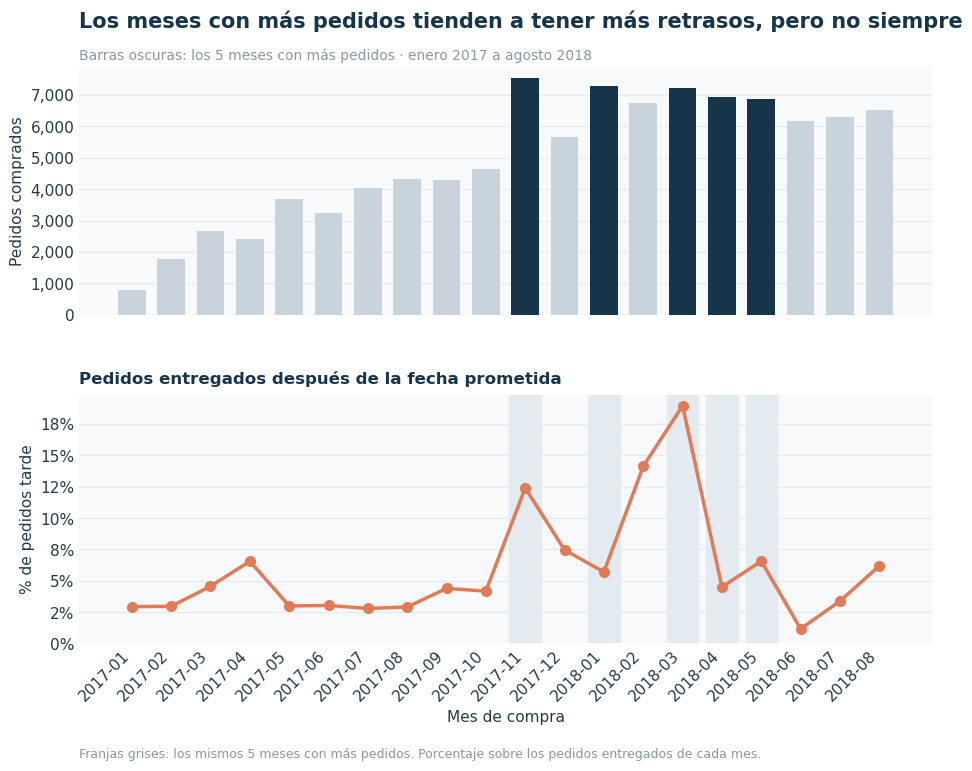

In [38]:
# Configuración del eje X y colores para resaltar los 5 meses con mayor volumen
x = np.arange(len(periodo))
colores_barras = [TEMA["azul"] if mes in mas_volumen else "#C9D3DB" for mes in periodo.index]

# Arriba: barras de volumen mensual de pedidos comprados
fig, (ax_pedidos, ax_tarde) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
ax_pedidos.bar(x, periodo["pedidos"], color=colores_barras, width=0.7, zorder=3)
ax_pedidos.set(title="Los meses con más pedidos tienden a tener más retrasos, pero no siempre",
               ylabel="Pedidos comprados")
subtitulo(ax_pedidos, "Barras oscuras: los 5 meses con más pedidos · enero 2017 a agosto 2018")
ax_pedidos.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:,.0f}"))
ax_pedidos.grid(axis="y", zorder=0)

# Abajo: franjas grises para los meses pico y línea de porcentaje de retrasos
for posicion, mes in enumerate(periodo.index):
    if mes in mas_volumen:
        ax_tarde.axvspan(posicion - 0.4, posicion + 0.4, color=TEMA["cuadricula"], zorder=1)
ax_tarde.plot(x, periodo["pct_tarde"], marker="o", markersize=7, linewidth=2.5, color=COLOR_TARDE, zorder=3)
ax_tarde.set_title("Pedidos entregados después de la fecha prometida", fontsize=12, pad=8)
ax_tarde.set(ylabel="% de pedidos tarde", xlabel="Mes de compra", ylim=(0, None))
ax_tarde.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.0f}%"))
ax_tarde.grid(axis="y", zorder=0)
ax_tarde.set_xticks(x, periodo.index.astype(str), rotation=45, ha="right")

nota(ax_tarde, "Franjas grises: los mismos 5 meses con más pedidos. Porcentaje sobre los pedidos entregados de cada mes.",
     y=-0.42)
fig.subplots_adjust(hspace=0.32)
guardar_figura(fig, "figura_8_pedidos_y_retrasos_por_mes.png")
plt.show()
plt.close(fig)

**Figura 8. Qué muestra.** Arriba, los pedidos de cada mes; abajo, el porcentaje de pedidos que llegaron tarde, con el mismo eje de meses. Las barras oscuras y las franjas grises marcan los 5 meses con más pedidos. Usamos dos paneles y no un solo gráfico con dos ejes verticales, porque las dos medidas tienen escalas distintas.

**Por qué importa.** El mes con más pedidos, **noviembre de 2017** (7,544, con el Black Friday), coincide con un salto del retraso a 12.4 %. Pero los peores meses son **febrero y marzo de 2018** (14.1 % y 19.0 %), y marzo fue el tercero en volumen, no el primero. En cambio, **junio de 2018** tuvo 6,167 pedidos y solo 1.2 % de retrasos.

**Limitaciones.** El volumen crece a lo largo del tiempo, así que la figura mezcla dos cosas: el volumen y todo lo demás que cambió en esos meses (capacidad de transporte, vendedores, fechas prometidas). Solo hay un noviembre en el periodo, así que no podemos confirmar que el patrón se repita cada año.

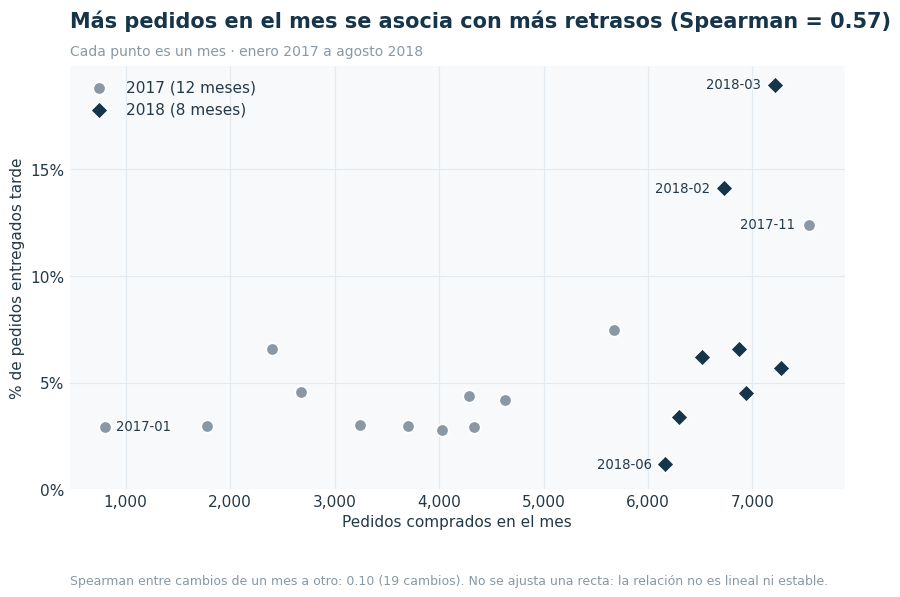

In [39]:
# Gráfico de dispersión: volumen mensual vs. % de retrasos, diferenciado por año
fig, ax = plt.subplots(figsize=(10, 5.5))
for anio, color, marcador in [(2017, TEMA["gris"], "o"), (2018, TEMA["azul"], "D")]:
    del_anio = periodo[periodo.index.year == anio]
    ax.scatter(del_anio["pedidos"], del_anio["pct_tarde"], s=80, marker=marcador, color=color,
               edgecolor="white", linewidth=1.2, zorder=3, label=f"{anio} ({len(del_anio)} meses)")

# Anotación de meses clave en la dispersión
destacados = {
    "2017-01": (8, "left"),
    "2017-11": (-10, "right"),
    "2018-02": (-10, "right"),
    "2018-03": (-10, "right"),
    "2018-06": (-10, "right"),
}
for mes, (desplazamiento, alineacion) in destacados.items():
    fila = periodo.loc[mes]
    ax.annotate(mes, (fila["pedidos"], fila["pct_tarde"]), xytext=(desplazamiento, 0),
                textcoords="offset points", ha=alineacion, va="center",
                color=TEMA["tinta"], fontsize=9.5)

# Configuración de la figura
ax.set(
    ylim=(0, None),
    title=f"Más pedidos en el mes se asocia con más retrasos (Spearman = {rho_mensual:.2f})",
    xlabel="Pedidos comprados en el mes",
    ylabel="% de pedidos entregados tarde",
)
subtitulo(ax, "Cada punto es un mes · enero 2017 a agosto 2018")
ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:,.0f}"))
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.0f}%"))
ax.grid(zorder=0)
ax.legend(frameon=False, loc="upper left")


nota(ax, f"Spearman entre cambios de un mes a otro: {rho_cambios:.2f} ({len(cambios)} cambios). "
         "No se ajusta una recta: la relación no es lineal ni estable.")
guardar_figura(fig, "figura_9_volumen_contra_retrasos.png")
plt.show()
plt.close(fig)

**Figura 9. Qué muestra.** Cada punto es un mes: a la derecha, los meses con más pedidos; arriba, los meses con más retrasos. Los meses de 2017 (gris) se concentran abajo a la izquierda, salvo noviembre y diciembre; todos los de 2018 (azul) tienen más de 6,000 pedidos.

**Por qué importa.** Ningún mes con menos de 5,000 pedidos superó el 7 % de retrasos, pero entre los meses con más de 6,000 pedidos hay de todo: desde 1.2 % hasta 19.0 %. Un volumen alto parece una condición para que haya muchos retrasos, pero no basta para causarlos.

**Limitaciones.** Son solo 20 puntos y no se ajusta ninguna recta, porque la relación no es lineal ni estable. La correlación describe meses, no pedidos individuales: no permite decir que un pedido comprado en un mes de mucho volumen tenga más riesgo de llegar tarde.

### 4.3 Respuesta a la pregunta 2

- **Sí hay una asociación positiva y moderada** entre el volumen mensual y los retrasos: Spearman de 0.57 en 20 meses, que se mantiene entre 0.51 y 0.66 al quitar cualquier mes. En los 5 meses con más pedidos, el 9.7 % de los pedidos entregados llegó tarde, contra 5.1 % en el resto.
- **No es una relación mes a mes:** cuando el volumen sube de un mes al siguiente, el retraso no sube necesariamente (Spearman de los cambios de 0.10).
- **El ejemplo más claro es noviembre de 2017**, con el récord de pedidos (y su día pico, el Black Friday) y 12.4 % de retrasos. Pero el peor periodo, febrero y marzo de 2018, no fue el de más pedidos, y junio de 2018 tuvo mucho volumen y casi ningún retraso.
- **Alcance:** el volumen alto acompaña a los retrasos, pero no los explica por sí solo. Con 20 meses y una tendencia de crecimiento, no podemos separar el efecto del volumen de otros cambios en el tiempo. El porcentaje de retraso se calcula sobre los pedidos entregados, que son entre 92.9 % y 98.9 % de los pedidos de cada mes.

## 5. Conclusiones

### 5.1 Respuestas a las preguntas

| Pregunta | Evidencia | Respuesta |
|---|---|---|
| 1. ¿Cómo se relaciona el tiempo de entrega con la satisfacción? | Figuras 1 a 7: estrellas por tramo, Spearman, puntualidad con el mismo tiempo, tramos de un día, fecha prometida y momento de la respuesta | A más tiempo, peor calificación (Spearman −0.235). La asociación más fuerte es con **incumplir la fecha prometida**: con un tiempo similar, los tardíos tienen 3.4 a 4 veces más reseñas bajas. Ese castigo se expresa sobre todo en respuestas dadas antes de recibir el pedido. |
| 2. ¿Los meses de más volumen tienen más retrasos? | Figuras 8 y 9: serie mensual, Spearman entre niveles, entre cambios y al quitar un mes | Asociación **positiva y moderada** entre niveles (0.57; de 0.51 a 0.66 al quitar un mes), pero **no mes a mes** (0.10). El volumen alto acompaña a los retrasos sin explicarlos por sí solo. |

### 5.2 Conclusión general

Para el cliente, la entrega importa sobre todo como **promesa**: mientras el pedido llega antes de la fecha prometida, unos días más casi no cambian la calificación; cuando la fecha se rebasa, las reseñas bajas se multiplican, y la mayor parte de ese castigo se registra mientras el cliente todavía espera, porque la encuesta le llega antes que el pedido. A escala mensual, los meses de más pedidos tienden a tener más retrasos, pero la relación no es estable mes a mes y no permite atribuir los retrasos al volumen.

Las dos conclusiones dependen de decisiones explícitas: qué reseña representa a cada pedido, qué fecha indica cuándo respondió el cliente, cómo se define "tarde" y qué denominador tiene cada porcentaje. Las comprobaciones de sensibilidad muestran cuáles de esas decisiones cambian los resultados (el momento de la respuesta) y cuáles no (la regla de reseña).

### 5.3 Limitaciones

1. **Diseño observacional.** No hay asignación aleatoria de retrasos: las asociaciones no demuestran causalidad.
2. **Selección.** La pregunta 1 describe 95,824 de los 99,441 pedidos (entregados y con reseña); los pedidos no entregados o sin reseña podrían tener otra experiencia.
3. **Escala ordinal.** Las estrellas tienen orden, pero no distancias iguales; el umbral de 1–2 estrellas es una decisión nuestra.
4. **Fechas administrativas.** La hora de entrega y la de respuesta son registros del sistema; no revelan por qué ni en qué circunstancias respondió cada cliente.
5. **Factores no controlados.** Producto, vendedor, región, precio y la propia fecha prometida pueden influir en la puntualidad y en la calificación.
6. **Serie mensual corta.** 20 meses con tendencia de crecimiento y un solo noviembre; la tasa se calcula sobre pedidos entregados. Lo observado en meses no se traslada a pedidos individuales.

### 5.4 Registro completo de decisiones

In [40]:
decisiones = pd.DataFrame(registro)
display(decisiones)

,paso,tabla,criterio,filas_afectadas,accion,limitacion
0,Decisión 1,orders,estado distinto de delivered o sin fecha de en...,2971,excluir de la base; no imputar fechas,el análisis describe solo pedidos entregados
1,Decisión 2,orders,alguna etapa negativa o faltante,1388,conservar: las fechas intermedias no se usan e...,no se conoce la causa de las inconsistencias
2,Decisión 3,orders,tiempo total mayor a 100 días,64,conservar; resumir con mediana y percentiles,un valor atípico no es necesariamente un error
3,Decisión 4,orders,"entregado el día prometido, después de las 00:00",1292,contar como a tiempo: se compara por día de ca...,difiere del criterio de olist_tools.py (dias_r...
4,Decisión 5,reviews,pedido con más de una reseña,551,conservar la última respuesta (review_answer_t...,no se afirma que sea la más verdadera; se comp...
5,Decisión 6,reviews,pedido entregado sin reseña,646,excluir solo del análisis de calificación,no se imputan calificaciones
6,Decisión 7,reviews,respuesta registrada antes de la entrega,4653,conservar y marcar; repetir resultados sin ell...,quitarlas excluye 70 % de los pedidos tardíos ...
7,Decisión 8,orders,meses incompletos al inicio (2016) y al final ...,349,analizar de enero 2017 a agosto 2018 (20 meses),solo hay un noviembre y un periodo de 20 meses


### 5.5 Verificación final

Comprobaciones de integridad que deben cumplirse al ejecutar el notebook de principio a fin (*Restart* y *Run All*).

In [41]:
# Listado ordenado de las figuras PNG generadas en resultados
figuras = sorted(ruta.name for ruta in CARPETA_RESULTADOS.glob("figura_*.png"))
validaciones = {
    "order_id único en orders": pedidos["order_id"].is_unique,
    "una reseña por pedido en el análisis": calificados["order_id"].is_unique,
    "calificaciones entre 1 y 5": calificados["review_score"].between(1, 5).all(),
    "tiempos totales no negativos": calificados["total_dias"].ge(0).all(),
    "los tramos cubren todos los pedidos calificados": por_tramo["pedidos"].sum() == len(calificados),
    "los 4 grupos de momento cubren todos los pedidos calificados": momento["pedidos"].sum() == len(calificados),
    "el volumen mensual suma todos los pedidos": mensual["pedidos"].sum() == len(pedidos),
    "20 meses consecutivos": len(periodo) == 20,
    "9 figuras generadas": len(figuras) == 9,
}
display(pd.Series(validaciones, name="correcto").to_frame())
assert all(validaciones.values()), "Alguna verificación falló."
print("Figuras en resultados/:")
for nombre in figuras:
    print(" ·", nombre)

,correcto
order_id único en orders,True
una reseña por pedido en el análisis,True
calificaciones entre 1 y 5,True
tiempos totales no negativos,True
los tramos cubren todos los pedidos calificados,True
los 4 grupos de momento cubren todos los pedidos calificados,True
el volumen mensual suma todos los pedidos,True
20 meses consecutivos,True
9 figuras generadas,True


Figuras en resultados/:
 · figura_1_distribucion_tiempo_entrega.png
 · figura_2_estrellas_por_tiempo.png
 · figura_3_puntualidad_mismo_tiempo.png
 · figura_4_brecha_por_dia.png
 · figura_5_promesa_y_calificacion.png
 · figura_6_momento_de_la_respuesta.png
 · figura_7_filtro_temporal.png
 · figura_8_pedidos_y_retrasos_por_mes.png
 · figura_9_volumen_contra_retrasos.png


**Fin del análisis.** Para reconstruir todas las tablas y figuras, reiniciar el kernel y ejecutar todas las celdas desde el inicio.

## Registro de contribuciones del equipo

**Proyecto: Análisis de logística y satisfacción del cliente — Olist**

| Integrante | Contribuciones y responsabilidades |
|---|---|
| **Carlos** | Análisis descriptivo de los tiempos de entrega y satisfacción del cliente. Elaboración de estadísticas descriptivas, análisis de correlaciones y comparación de calificaciones según el desempeño logístico. |
| **Esmeralda** | Preparación del entorno, carga de archivos y exploración inicial de datos. Revisión de llaves, estados de pedidos, fechas y valores faltantes. Documentación del diccionario de variables, tipos de datos y criterios de calidad. |
| **Emiliano** | Análisis de puntualidad de las entregas, cumplimiento de fechas prometidas y relación entre el momento de las encuestas y las calificaciones. Desarrollo de pruebas de sensibilidad e interpretación de resultados. |
| **Miguel Ángel** | Evaluación de la calidad de los datos, cálculo de tiempos de entrega y definición de retrasos. Tratamiento de reseñas, identificación de inconsistencias y validación de los datos preparados para el análisis. |
| **Pamela** | Análisis del volumen mensual de pedidos y retrasos. Evaluación de correlaciones, elaboración de visualizaciones y revisión de los resultados del proyecto. |
| **Todo el equipo** | Selección y definición conjunta de las preguntas de investigación. Identificación y corrección de errores durante el desarrollo del análisis. **Elaboración conjunta del código.** Validación de la reproducibilidad del notebook y correcta ejecución del código. Revisión, discusión e interpretación colaborativa de los resultados obtenidos, así como elaboración conjunta de las conclusiones finales del proyecto. |